# **End-to-End Machine Learning Project**

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# 📖 TABLE OF CONTENTS

- [Main Steps of a Machine Learning Project](#Main-Steps-of-a-Machine-Learning-Project)
- [Look at the Big Picture](#Look-at-the-Big-Picture)
  - [Frame the Problem](#Frame-the-Problem)
  - [Select a Performance Measure](#Select-a-Performance-Measure)
  - [Check the Assumptions](#Check-the-Assumptions)
- [Get the Data](#Get-the-Data)
  - [Download the Data](#Download-the-Data)
  - [Take a Quick Look at the Data Structure](#Take-a-Quick-Look-at-the-Data-Structure)
  - [Create a Test Set](#Create-a-Test-Set)
    - [Random Split without seed](#Random-Split-without-seed)
    - [Random Split with seed](#Random-Split-with-seed)
    - [Deterministic Split using Hashing](#Deterministic-Split-using-Hashing)
    - [Stratified Sampling](#Stratified-Sampling)
- [Explore and Visualize the Data to Gain Insights](#Explore-and-Visualize-the-Data-to-Gain-Insights)
  - [Visualizing Geographical Data](#Visualizing-Geographical-Data)
  - [Look for Correlations](#Look-for-Correlations)
  - [Experiment with Attribute Combinations](#Experiment-with-Attribute-Combinations)
- [Prepare the Data for Machine Learning Algorithms](#Prepare-the-Data-for-Machine-Learning-Algorithms)
  - [Clean the Data](#Clean-the-Data)
    - [Scikit-Learn Design](#Scikit-Learn-Design)
  - [Handling Text and Categorical Attributes](#Handling-Text-and-Categorical-Attributes)
  - [Feature Scaling and Transformation](#Feature-Scaling-and-Transformation)
  - [Custom Transformers](#Custom-Transformers)
  - [Transformation Pipelines](#Transformation-Pipelines)
- [Select and Train a Model](#Select-and-Train-a-Model)
  - [Train and Evaluate on the Training Set](#Train-and-Evaluate-on-the-Training-Set)
  - [Better Evaluation Using Cross-Validation](#Better-Evaluation-Using-Cross-Validation)
- [Fine-Tune Your Model](#Fine-Tune-Your-Model)
  - [Grid Search](#Grid-Search)
  - [Randomized Search](#Randomized-Search)
  - [Ensemble Methods](#Ensemble-Methods)
  - [How to Choose the Sampling Distribution for a Hyperparameter](#How-to-Choose-the-Sampling-Distribution-for-a-Hyperparameter)
- [References](#References)

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Main Steps of a Machine Learning Project

Main steps of a machine learning project are:
* Look at the big picture.
* Get the data.
* Explore and visualize the data to gain insights.
* Prepare the data for machine learning algorithms.
* Select and train a model.
* Fine-tune your model.
* Launch, monitor, and maintain your system.

**Note: Use [ML Project Checklist](https://github.com/ancilcleetus/My-Learning-Journey-in-AI/blob/main/Fundamentals-of-Machine-Learning/ml-project-checklist.md) as a helper for executing the above steps.**

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Look at the Big Picture

Our task is to use California Housing Prices data to build a model of housing prices in the state. This data includes metrics such as the population, median income, and median housing price for each block group in California. Block groups are the smallest geographical unit for which the US Census Bureau publishes sample data (a block group typically has a population of 600 to 3,000 people). We will call them “districts” for short. Our model should learn from this data and be able to predict the median housing price in any district, given all the other metrics.

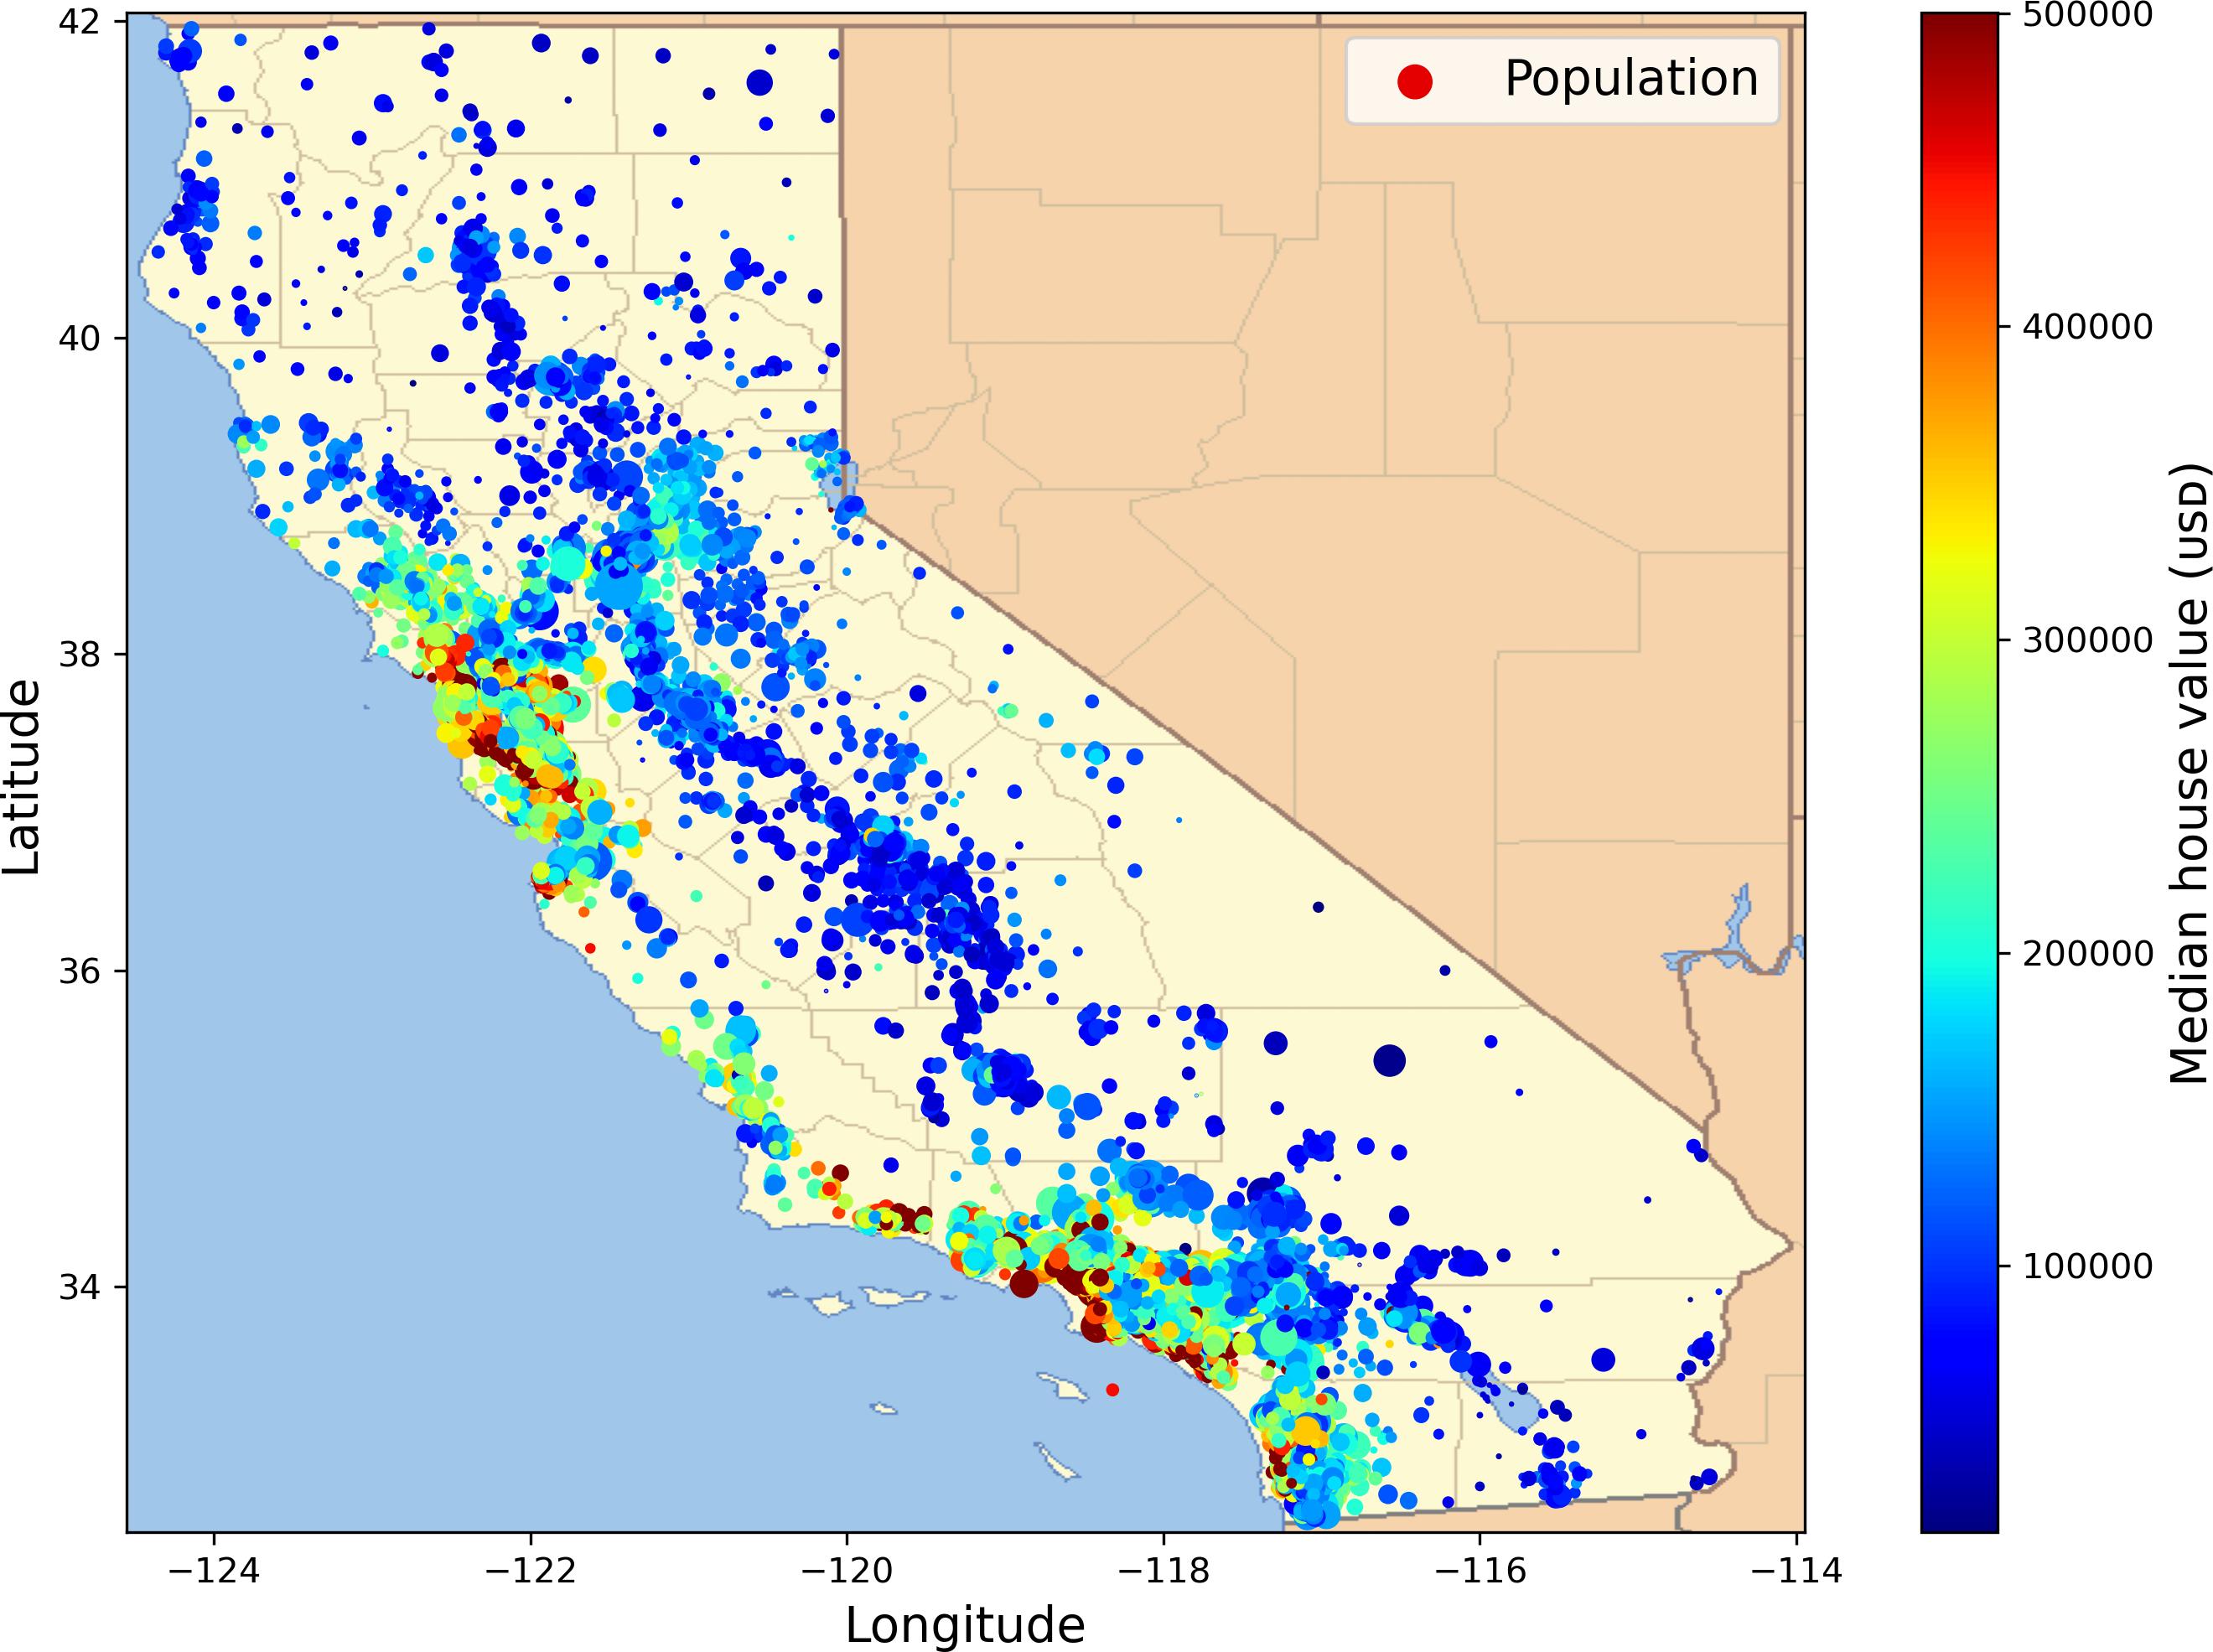

*California housing prices*

In [1]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/end_to_end_ml_project_01.png", width=500))
display(Markdown("*California housing prices*"))

## Frame the Problem

1. What exactly is the business objective? How does the company expect to use and benefit from this model?

    **Note:** *Knowing the objective is important because it will determine how you frame the problem, which algorithms you will select, which performance measure you will use to evaluate your model, and how much effort you will spend tweaking it.*
    
    **Answer:** Your boss answers that your model's output (a prediction of a district's median housing price) will be essential to determine whether it is worth investing in a given area. More specifically, your model's output will be fed to another machine learning system (see below figure), along with some other signals. So it's important to make our housing price model as accurate as we can.

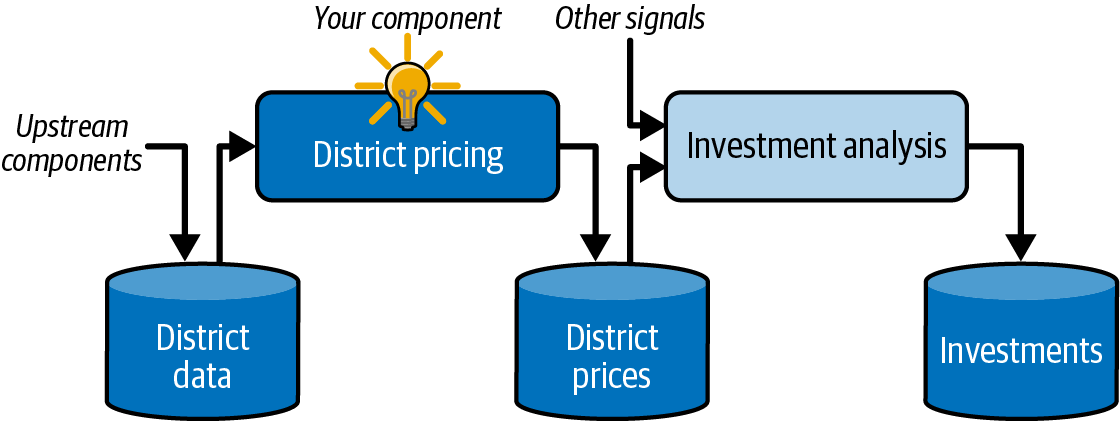

*A machine learning pipeline for real estate investments*

In [2]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/end_to_end_ml_project_02.png", width=500))
display(Markdown("*A machine learning pipeline for real estate investments*"))

2. What are the current solutions/workarounds (if any)?

    **Note:** *The current situation will often give you a reference for performance, as well as insights on how to solve the problem.*
    
    **Answer:** Your boss answers that the district housing prices are currently estimated manually by experts: a team gathers up-to-date information about a district, and when they cannot get the median housing price, they estimate it using complex rules.

    This is costly and time-consuming, and their estimates are not great; in cases where they manage to find out the actual median housing price, they often realize that their estimates were off by more than 30%. This is why the company thinks that it would be useful to train a model to predict a district’s median housing price, given other data about that district.

3. How should you frame this problem (supervised/unsupervised, classification task/regression task, online learning/offline learning, etc.)?

    **Answer:**
    * Learning Mode
        * Supervised learning
        * Regression task
            * System uses multiple features for prediction => Multiple regression problem
            * Predict only a single value => Univariate regression problem
    * Training Mode
        * No continuous data coming into the system => no need to rapidly adapt model to changing data
        * Data is small to fit in memory
        * Hence, Offline/Batch learning

## Select a Performance Measure

* A typical performance measure for regression problems => Root Mean Squared Error (RMSE)
    * Higher weight given to larger errors
    * Quite sensitive to outliers => Not preferred if many outliers in the data
    * Equation for RMSE is $\text{RMSE}(\textbf{X}, \textbf{y}, h) = \sqrt{\frac{1}{m} \sum_{i=1}^{m} \left( h(\textbf{x}^{(i)}) - y^{(i)} \right)^2}$ where

        * $m$ => number of instances in the dataset
    
        * $\textbf{x}^{(i)}$ => vector of all the feature values (excluding the label) of the ${i}^{th}$ instance in the dataset
    
        * $y^{(i)}$ => label of ${i}^{th}$ instance in the dataset
    
        * $\textbf{X}$ is a matrix containing all the feature values (excluding labels) of all instances in the dataset. In matrix $\textbf{X}$, ${i}^{th}$ row is equal to $(\textbf{x}^{(i)})^{T}$, the transpose of $\textbf{x}^{(i)}$.
    
        * $h$ is the prediction function of the system; ${\widehat{y}}^{(i)} = h(\textbf{x}^{(i)})$
* Many outliers in the data => Can consider Mean Absolute Error (MAE)
    * Equation for MAE is $\text{MAE}(\textbf{X}, \textbf{y}, h) = \frac{1}{m} \sum_{i=1}^{m} \left| h(\textbf{x}^{(i)}) - y^{(i)} \right|$

___

**Note 1:** We use lowercase italic font for scalar values (such as $m$ or $y^{(i)}$) and function names (such as $h$), lowercase bold font for vectors (such as $\textbf{x}^{(i)}$), and uppercase bold font for matrices (such as $\textbf{X}$).

**Note 2:** $l_k$ norm of a vector $\textbf{v}$ containing $n$ elements is defined as $\left\| \textbf{v} \right\|_k = (\left| v_1 \right|^k + \left| v_2 \right|^k + ... + \left| v_n \right|^k)^{1/k}$. RMSE corresponds to $l_2$ norm or Euclidean norm while MAE corresponds to $l_1$ norm or Manhattan norm. $l_0$ gives the no of nonzero elements in the vector while $l_∞$ gives the maximum absolute value in the vector.

**Note 3:** When outliers are exponentially rare, the RMSE performs very well and is generally preferred.

___

## Check the Assumptions

**Note:** *It is good practice to list and verify the assumptions that have been made so far (by you or others); this can help you catch serious issues early on.*

For example, let the downstream ML system converts housing prices output by our ML system to three categories (cheap, medium & expensive) and then uses those categories instead of the prices themselves. In this case, getting the price perfectly right is not important at all; your system just needs to get the category right. Then the problem should have been framed as a classification task, not a regression task. You don't want to find this out after working on a regression system for months.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Get the Data

## Download the Data

* In most environments, data will be stored in a relational database or some other common data store & spread across multiple tables or files.
* Rather than manually downloading and decompressing the data, it's usually preferable to write a function that does it for you. This is useful in particular if the data changes regularly. You can also set up a scheduled job to do that automatically at regular intervals.

Function to fetch and load the data is given below:

In [3]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_full = load_housing_data()

## Take a Quick Look at the Data Structure

In [4]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


**Note 1:** There are 20,640 instances in the dataset, which means that it is fairly small by machine learning standards, but it's perfect to get started. You notice that the `total_bedrooms` attribute has only 20,433 non-null values, meaning that 207 districts are missing this feature. You will need to take care of this later.

**Note 2:** All attributes are numerical, except for `ocean_proximity`. Its type is `object`, so it could hold any kind of Python object. It looks like a categorical attribute. You can find out what categories exist and how many districts belong to each category by using the `value_counts()` method.

In [6]:
housing_full["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


The `describe()` method shows a summary of the numerical attributes.

In [7]:
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Another quick way to get a feel of the type of data you are dealing with is to plot a histogram for each numerical attribute. You can either plot this one attribute at a time, or you can call the `hist()` method on the whole dataset (as shown in the following code example), and it will plot a histogram for each numerical attribute. The number of value ranges can be adjusted using the `bins` argument.

In [8]:
import matplotlib.pyplot as plt

# extra code – the next 5 lines define the default font sizes
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=8)
plt.rc('ytick', labelsize=8)

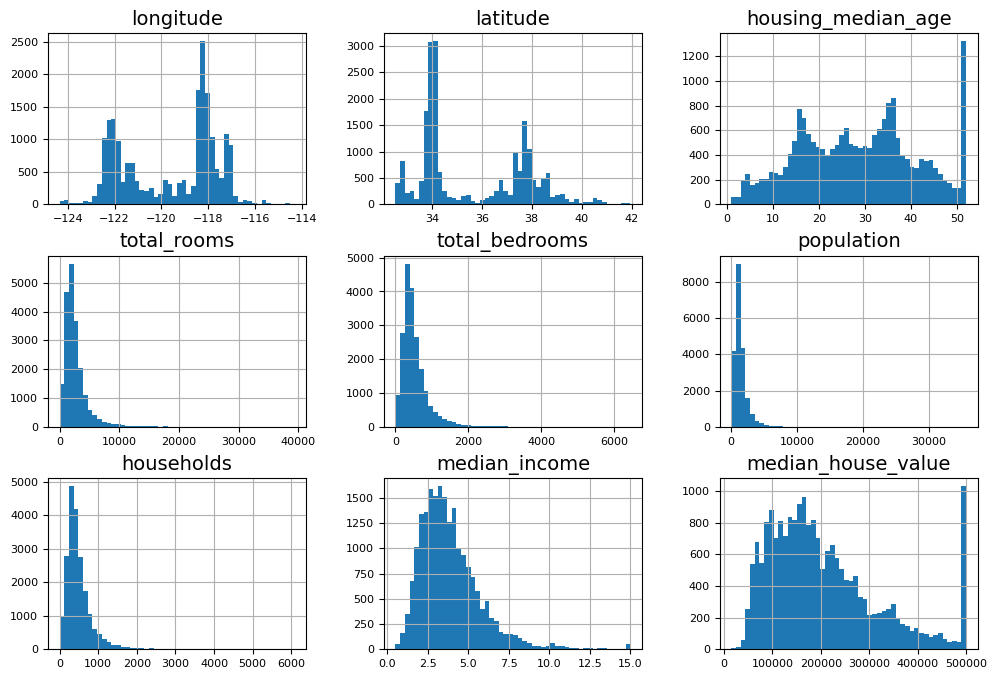

In [9]:
housing_full.hist(bins=50, figsize=(12, 8))
plt.show()

Looking at these histograms, you notice a few things:

* The `median_income` attribute is expressed in tens of thousands of dollars.
* The `median_income` attribute is scaled and capped at 15 (actually, 15.0001) for higher median incomes, and at 0.5 (actually, 0.4999) for lower median incomes.
* The `housing_median_age` and the `median_house_value` were also capped. The `median_house_value` attribute may be a serious problem since it is your target attribute. Your machine learning algorithms may learn that prices never go beyond that limit. If we need precise predictions even beyond $500,000, then you have two options:
    * Collect proper labels for the districts whose labels were capped.
    * Remove those districts from the training set (and also from the test set, since your system should not be evaluated poorly if it predicts values beyond $500,000).
* Many histograms are skewed right: they extend much farther to the right of the median than to the left. This may make it a bit harder for some machine learning algorithms to detect patterns. Later, you'll try transforming these attributes to have more symmetrical and bell-shaped distributions.

## Create a Test Set

* Before you look at the data any further, you need to create a test set, put it aside, and never look at it. If you look at this test set, you may find some patterns in it and may select an ML model suited for this test set. Hence, your generalization error estimate will be too optimistic leading to an ML model not working well as expected in production. This is called Data Snooping Bias.
* Creating a test set is theoretically simple; pick some instances randomly, typically 20% of the dataset (or less if your dataset is very large), and set them aside.

### Random Split without seed

In [10]:
import numpy as np

def shuffle_and_split_data(data, test_ratio, rng):
    shuffled_indices = rng.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

In [11]:
rng = np.random.default_rng()
train_set, test_set = shuffle_and_split_data(housing_full, 0.2, rng)
print(f'len(train_set): {len(train_set)}')
print(f'len(test_set): {len(test_set)}')

len(train_set): 16512
len(test_set): 4128


### Random Split with seed

Well, this works, but it is not perfect: if you run the program again, it will generate a different test set! Over time, you (or your machine learning algorithms) will get to see the whole dataset, which is what you want to avoid.

To ensure that this notebook's outputs remain the same every time we run it, we need to set the random number generator’s seed:

In [12]:
rng = np.random.default_rng(seed=42)
train_set, test_set = shuffle_and_split_data(housing_full, 0.2, rng)
print(f'len(train_set): {len(train_set)}')
print(f'len(test_set): {len(test_set)}')

len(train_set): 16512
len(test_set): 4128


### Deterministic Split using Hashing

* However, both these solutions will break the next time you fetch an updated dataset. We want a split that:
    * ✅ Is deterministic
    * ✅ Does not change when new data is added
    * ✅ Keeps old training data out of the test set forever
    * ✅ Automatically assigns ~20% of new data to test

* To have a stable train/test split even after updating the dataset, a common solution is to use each instance’s identifier to decide whether it should go in the test set (assuming instances have unique and immutable identifiers). For example, you could compute a hash of each instance’s identifier and put that instance in the test set if the hash is lower than or equal to 20% of the maximum hash value. This ensures that the test set will remain consistent across multiple runs, even if you refresh the dataset. The new test set will contain 20% of the new instances, but it will not contain any instance that was previously in the training set.

In [13]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

Unfortunately, the housing dataset does not have an identifier column. The simplest solution is to use the row index as the ID:

In [14]:
housing_with_id = housing_full.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")
print(f'len(train_set): {len(train_set)}')
print(f'len(test_set): {len(test_set)}')

len(train_set): 16512
len(test_set): 4128


If you use the row index as a unique identifier, you need to make sure that new data gets appended to the end of the dataset and that no row ever gets deleted. If this is not possible, then you can try to use the most stable features to build a unique identifier. For example, a district’s latitude and longitude are guaranteed to be stable for a few million years, so you could combine them into an ID like so:⁠

In [15]:
housing_with_id["id"] = (housing_full["longitude"] * 1000
                         + housing_full["latitude"])
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")
print(f'len(train_set): {len(train_set)}')
print(f'len(test_set): {len(test_set)}')

len(train_set): 16322
len(test_set): 4318


**Note:** Scikit-Learn provides a few functions to split datasets into multiple subsets in various ways. The simplest function is `train_test_split(),` which does pretty much the same thing as the `shuffle_and_split_data()` function we defined earlier, with a couple of additional features.

In [16]:
from sklearn.model_selection import train_test_split

train_set_, test_set_ = train_test_split(housing_full, test_size=0.2,
                                       random_state=42)
print(f'len(train_set_): {len(train_set_)}')
print(f'len(test_set_): {len(test_set_)}')

len(train_set_): 16512
len(test_set_): 4128


### Stratified Sampling

* Large dataset => Random sampling is fine
* Test set should be representative of the overall population => Stratified sampling preferred
* In Stratified sampling,
    * Population is divided into homogeneous subgroups called strata
    * A particular no of instances from each strata is included in test set based on the distribution of strata in the population

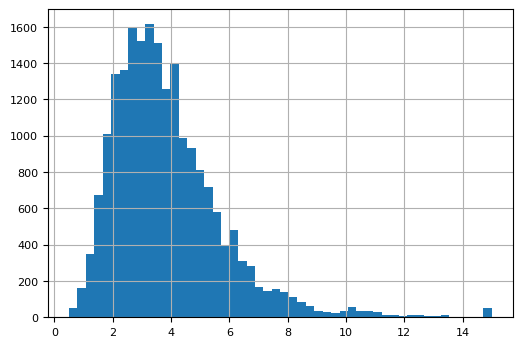

In [17]:
housing_full['median_income'].hist(bins=50, figsize=(6, 4))
plt.show()

* From expert opinions, `median_income` is a very important attribute to predict `median_house_value`. Hence, our test set should be representative of districts with all the ranges of median income.
* From the histogram of `median_income`, we can see that most districts have median income ranging from 1.5 to 6 (i.e. \$15000 to \$60000). We also have incomes below 1.5 and above 6. We need to create strata based on this.
* It is important to have a sufficient number of instances in your dataset for each stratum, or else the estimate of a stratum’s importance may be biased. This means that you should not have too many strata, and each stratum should be large enough.
* We create an income category attribute `income_cat` with five categories (labeled from 1 to 5).
    * Category 1 => 0 to 1.5
    * Category 2 => 1.5 to 3
    * Category 3 => 3 to 4.5
    * Category 4 => 4.5 to 6
    * Category 5 => 6 to ∞

In [18]:
housing_full['income_cat'] = pd.cut(housing_full['median_income'],
                                     bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                     labels=[1, 2, 3, 4, 5])

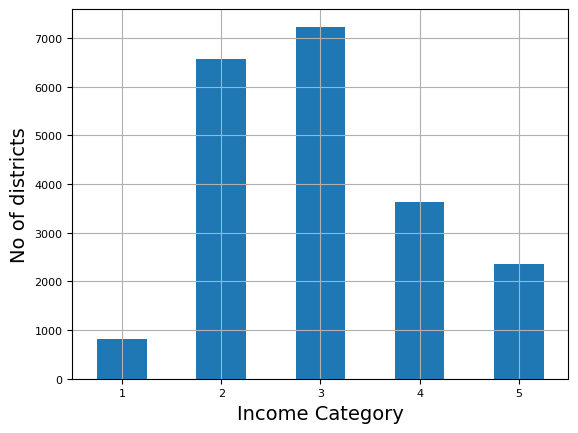

In [19]:
cat_counts = housing_full['income_cat'].value_counts().sort_index()
cat_counts.plot.bar(grid=True, rot=0)
plt.xlabel('Income Category')
plt.ylabel('No of districts')
plt.show()

Now you are ready to do stratified sampling based on the income category. Having multiple splits can be useful if you want to better estimate the performance of your model, as you will see when we discuss cross-validation.

In [20]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing_full,
                                              housing_full["income_cat"]):
    strat_train_set_n = housing_full.iloc[train_index]
    strat_test_set_n = housing_full.iloc[test_index]
    strat_splits.append([strat_train_set_n, strat_test_set_n])

strat_train_set, strat_test_set = strat_splits[0]  # Use first split
print(f'len(strat_train_set): {len(strat_train_set)}')
print(f'len(strat_test_set): {len(strat_test_set)}')

len(strat_train_set): 16512
len(strat_test_set): 4128


There’s a shorter way to get a single split using the `train_test_split()` function with the `stratify` argument.

In [21]:
strat_train_set, strat_test_set = train_test_split(
    housing_full, test_size=0.2, stratify=housing_full["income_cat"], random_state=42
)
print(f'len(strat_train_set): {len(strat_train_set)}')
print(f'len(strat_test_set): {len(strat_test_set)}')

len(strat_train_set): 16512
len(strat_test_set): 4128


We can compare the income category proportions in the full dataset vs stratified test set vs random test set.

In [22]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

from sklearn.model_selection import train_test_split

train_set_, test_set_ = train_test_split(housing_full, test_size=0.2,
                                       random_state=42)

compare_props = pd.DataFrame({
    "Full Dataset %": income_cat_proportions(housing_full),
    "Stratified Test Set %": income_cat_proportions(strat_test_set),
    "Random Test Set %": income_cat_proportions(test_set_),
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified Test Set %"] /
                                   compare_props["Full Dataset %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random Test Set %"] /
                                  compare_props["Full Dataset %"] - 1)
(compare_props * 100).round(2)

,Full Dataset %,Stratified Test Set %,Random Test Set %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


As you can see, the test set generated using stratified sampling has income category proportions almost identical to those in the full dataset, whereas the test set generated using purely random sampling is skewed.

You won’t use the `income_cat` column again, so you might as well drop it, reverting the data back to its original state:

In [23]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Explore and Visualize the Data to Gain Insights

Now, we need to dig deeper and get a really good understanding of the data. First, make sure you have put the test set aside and you are only exploring the training set. Also, if the training set is very large, you may want to sample an exploration set, to make manipulations easy and fast during the exploration phase. In this case, the training set is quite small, so you can just work directly on the full set. Since you’re going to experiment with various transformations of the full training set, you should make a copy of the original so you can revert to it afterwards:

In [24]:
housing = strat_train_set.copy()
print(f'len(housing): {len(housing)}')

len(housing): 16512


## Visualizing Geographical Data

Because the dataset includes geographical information (latitude and longitude), it is a good idea to create a scatterplot of all the districts to visualize the data:

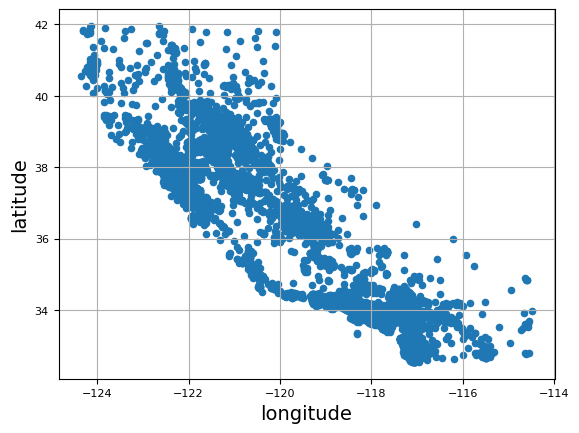

In [25]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True)
plt.show()

This looks like California all right, but other than that it is hard to see any particular pattern. Setting the alpha option to 0.2 makes it much easier to visualize the places where there is a high density of data points.

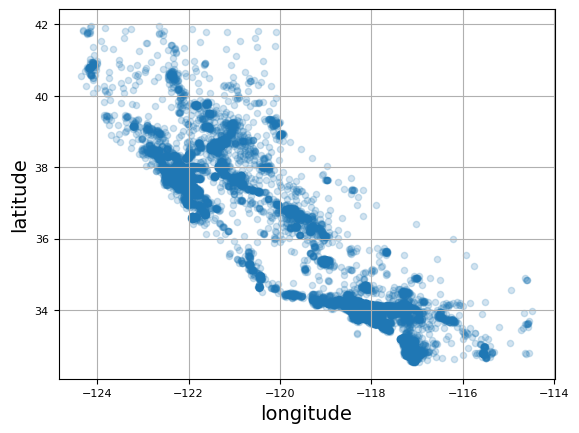

In [26]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True, alpha=0.2)
plt.show()

Next, you look at the housing prices. The radius of each circle represents the district’s population (option `s`), and the color represents the price (option `c`). Here you use a predefined color map (option `cmap`) called `jet`, which ranges from blue (low values) to red (high prices):

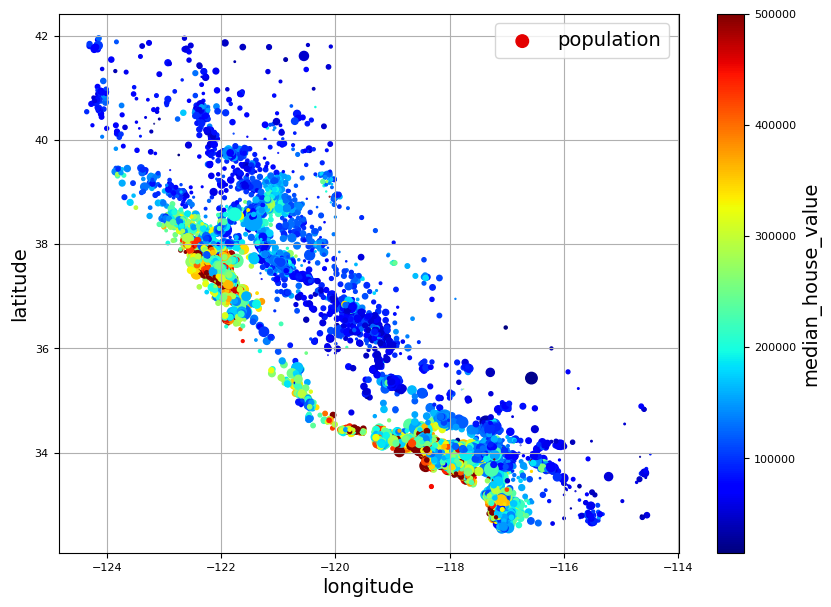

In [27]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
            s=housing["population"] / 100, label="population",
            c="median_house_value", cmap="jet", colorbar=True,
            legend=True, sharex=False, figsize=(10, 7))

plt.show()

This image tells you that the housing prices are very much related to the location (e.g., close to the ocean) and to the population density. A clustering algorithm should be useful for detecting the main cluster and for adding new features that measure the proximity to the cluster centers. The ocean proximity attribute may be useful as well, although in Northern California the housing prices in coastal districts are not too high, so it is not a simple rule.

## Look for Correlations

You can easily compute the *standard correlation coefficient* (also called Pearson's r) between every pair of numerical attributes using the `corr()` method:

In [28]:
corr_matrix = housing.corr(numeric_only=True)

Now you can look at how much each attribute correlates with the median house value:

In [29]:
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
longitude,-0.050859
latitude,-0.139584


* The correlation coefficient ranges from -1 to 1.
* Correlation coefficient close to 1 => strong positive correlation
    * Example: `median_house_value` tends to go up when the `median_income` goes up.
* Correlation coefficient close to -1 => strong negative correlation
    * Example: small negative correlation between `median_house_value` and `latitude` (i.e., prices have a slight tendency to go down when you go north).
* Correlation coefficient close to 0 => no linear correlation

Another way to check for correlation between attributes is to use the Pandas `scatter_matrix()` function, which plots every numerical attribute against every other numerical attribute.

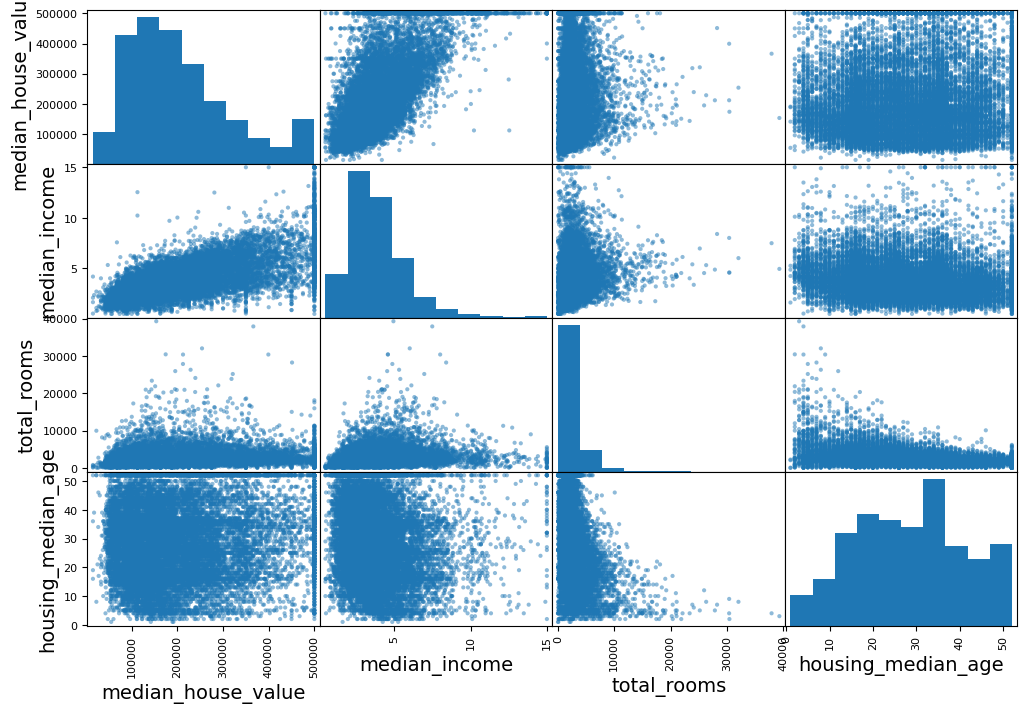

In [30]:
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms",
               "housing_median_age"]
scatter_matrix(housing[attributes], figsize=(12, 8))
plt.show()

The main diagonal would be full of straight lines if Pandas plotted each variable against itself, which would not be very useful. So instead, the Pandas displays a histogram of each attribute (other options are available; see the Pandas documentation for more details).

Looking at the correlation scatterplots, it seems like the most promising attribute to predict the `median_house_value` is the `median_income`.

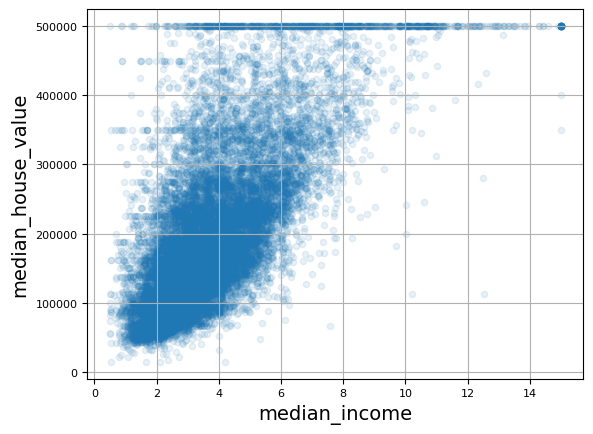

In [31]:
housing.plot(kind='scatter', x='median_income', y='median_house_value', alpha=0.1, grid=True)
plt.show()

* This plot reveals a few things.
    * First, the correlation is indeed quite strong; you can clearly see the upward trend, although the data is noisy.
    * Second, the price cap you noticed earlier is clearly visible as a horizontal line at $500,000.
    * But the plot also reveals other less obvious straight lines: a horizontal line around $450,000, another around $350,000, perhaps one around $280,000, and a few more below that. You may want to try removing the corresponding districts to prevent your algorithms from learning to reproduce these data quirks.

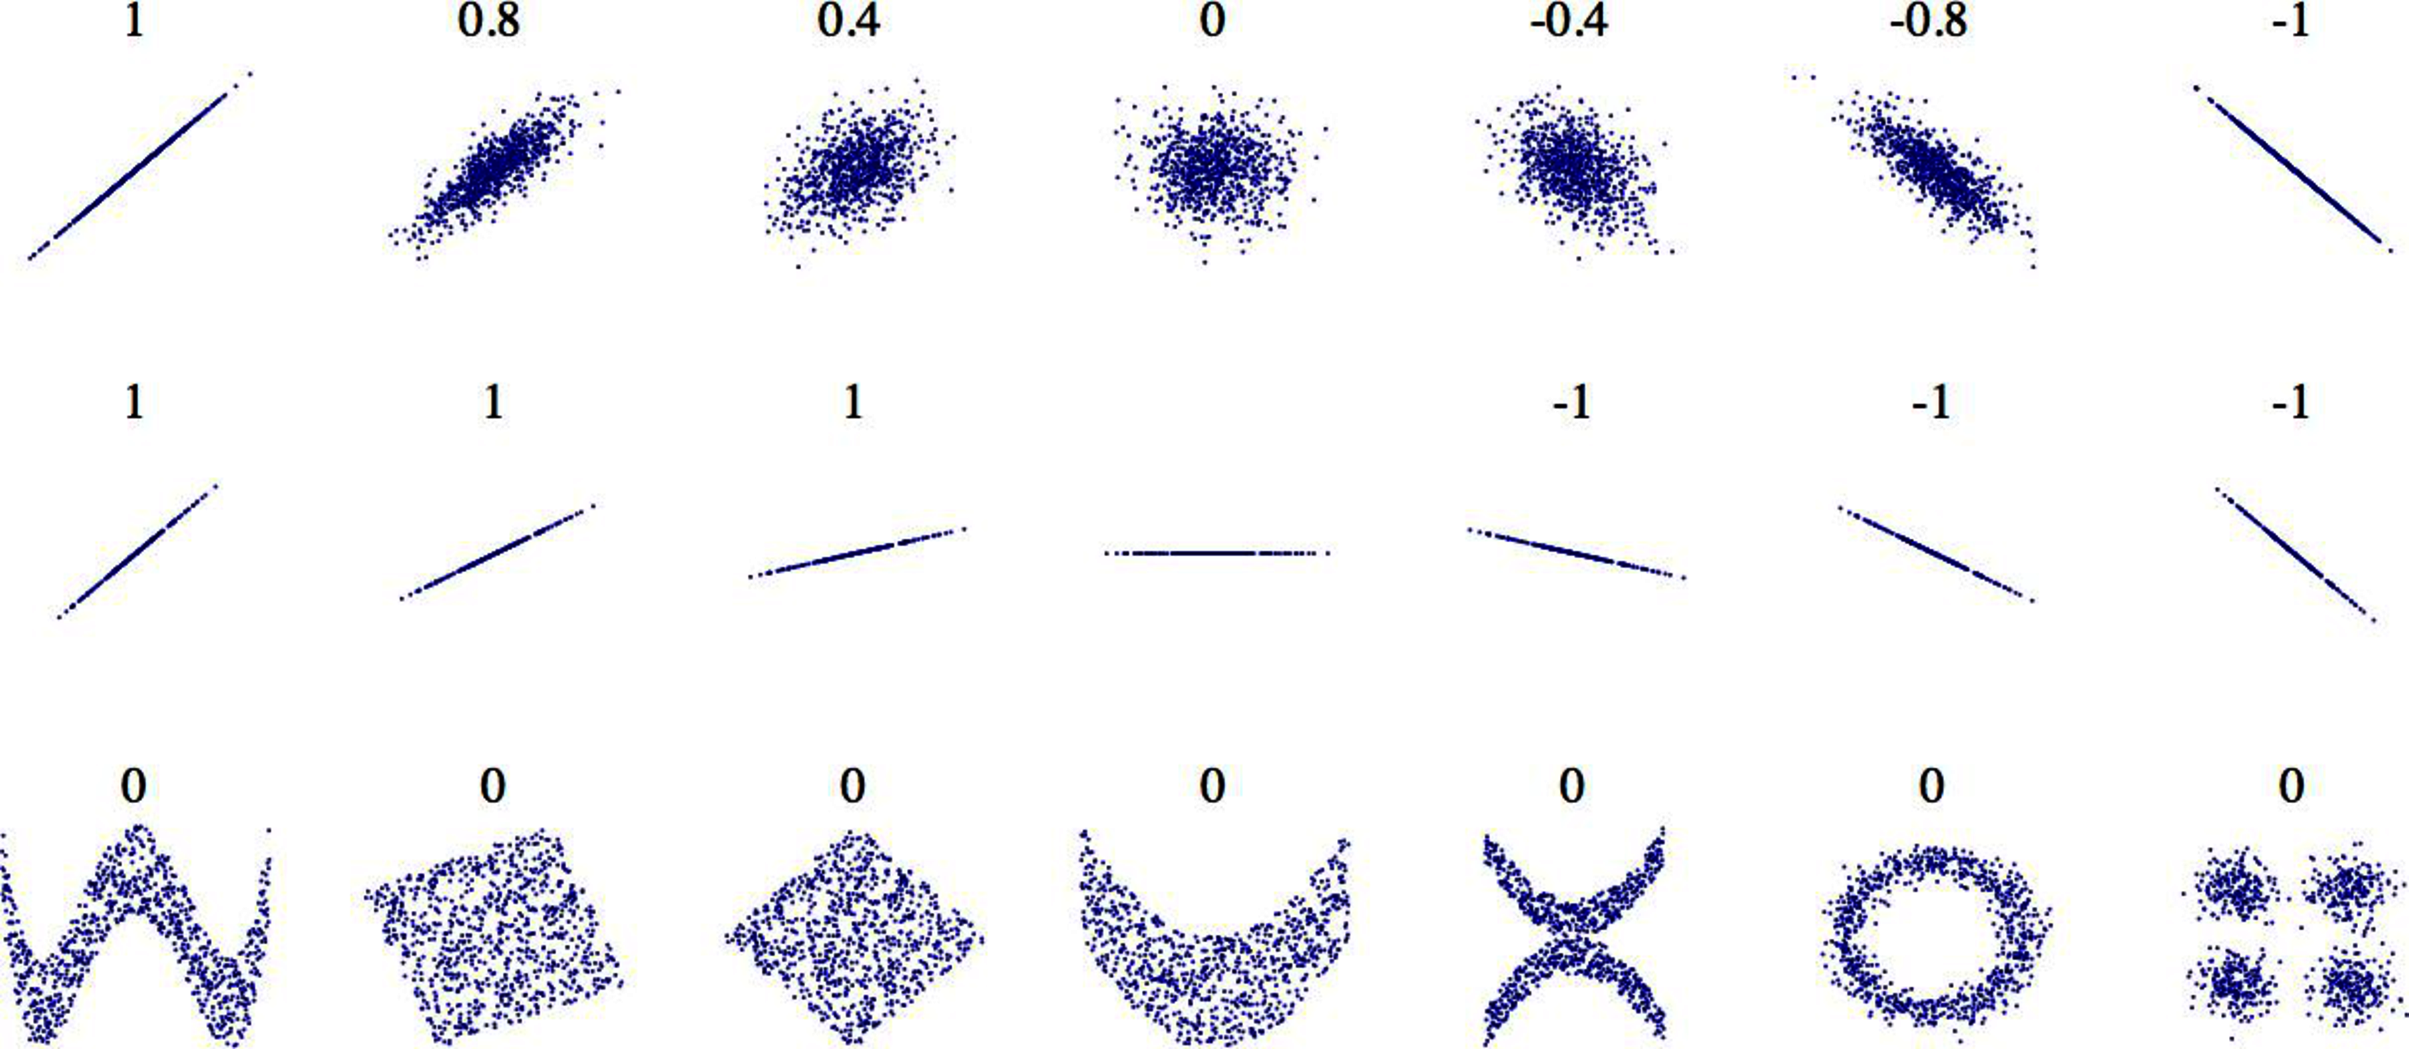

*Standard correlation coefficient of various datasets*

In [32]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/end_to_end_ml_project_03.png", width=500))
display(Markdown("*Standard correlation coefficient of various datasets*"))

Note that the correlation coefficient only measures linear correlations (“as x goes up, y generally goes up/down”). It may completely miss out on nonlinear relationships (e.g., “as x approaches 0, y generally goes up”). Figure above shows a variety of datasets along with their correlation coefficient. Note how all the plots of the bottom row have a correlation coefficient equal to 0, despite the fact that their axes are clearly not independent: these are examples of nonlinear relationships. Also, the second row shows examples where the correlation coefficient is equal to 1 or -1; notice that this has nothing to do with the slope. For example, your height in inches has a correlation coefficient of 1 with your height in feet or in nanometers.

## Experiment with Attribute Combinations

One last thing you may want to do before preparing the data for machine learning algorithms is to try out various attribute combinations. For example, the total number of rooms in a district is not very useful if you don't know how many households there are. What you really want is the number of rooms per household. Similarly, the total number of bedrooms by itself is not very useful: you probably want to compare it to the total number of rooms. And the population per household also seems like an interesting attribute combination to look at. You create these new attributes as follows:

In [33]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

And then you look at the correlation matrix again:

In [34]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.688380
rooms_per_house,0.143663
total_rooms,0.137455
housing_median_age,0.102175
households,0.071426
total_bedrooms,0.054635
population,-0.020153
people_per_house,-0.038224
longitude,-0.050859


The new `bedrooms_ratio` attribute is much more correlated with the median house value than the total number of rooms or bedrooms. It’s a strong negative correlation, so it looks like houses with a lower bedroom/room ratio tend to be more expensive. The number of rooms per household (`rooms_per_house`) is also more informative than the total number of rooms in a district (`total_rooms`) — obviously the larger the houses, the more expensive they are.

___

**Note**

*When creating new combined features, make sure they are not too linearly correlated with existing features: collinearity can cause issues with some models, such as linear regression. In particular, avoid simple weighted sums of existing features.*

**Note**

*This round of exploration does not have to be absolutely thorough; the point is to start off on the right foot and quickly gain insights that will help you get a first reasonably good prototype. But this is an iterative process: once you get a prototype up and running, you can analyze its output to gain more insights and come back to this exploration step.*

___

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Prepare the Data for Machine Learning Algorithms

It’s time to prepare the data for your machine learning algorithms. Instead of doing this manually, you should write functions for this purpose, for several good reasons:

* This will allow you to reproduce these transformations easily on any dataset (e.g., the next time you get a fresh dataset).

* You will gradually build a library of transformation functions that you can reuse in future projects.

* You can use these functions in your live system to transform the new data before feeding it to your algorithms.

* This will make it possible for you to easily try various transformations and see which combination of transformations works best.

But first, revert to a clean training set (by copying `strat_train_set` once again). You should also separate the predictors and the labels, since you don’t necessarily want to apply the same transformations to the predictors and the target values (note that `drop()` creates a copy of the data and does not affect `strat_train_set` unless you pass `inplace=True`):

In [35]:
housing = strat_train_set.drop("median_house_value", axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

## Clean the Data

Most machine learning algorithms cannot work with missing features, so you’ll need to take care of these. For example, you noticed earlier that the `total_bedrooms` attribute has some missing values. You have three options to fix this:

1. Get rid of the corresponding districts.

2. Get rid of the whole attribute.

3. Set the missing values to some value (zero, the mean, the median, etc.). This is called imputation.

You can accomplish these easily using the Pandas DataFrame’s `dropna()`, `drop()`, and `fillna()` methods:
* Option 1 => `housing.dropna(subset=["total_bedrooms"], inplace=True)`
* Option 2 => `housing.drop("total_bedrooms", axis=1, inplace=True)`
* Option 3 => `housing["total_bedrooms"] = housing["total_bedrooms"].fillna(median)`

For each option, we'll create a copy of `housing` and work on that copy to avoid breaking `housing`. We'll also show the output of each option, filtering on the rows that originally contained a NaN value.

In [36]:
null_rows_idx = housing.isnull().any(axis=1)
housing.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


In [37]:
housing_option1 = housing.copy()
housing_option1.dropna(subset=["total_bedrooms"], inplace=True)
housing_option1.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity


In [38]:
housing_option2 = housing.copy()
housing_option2.drop("total_bedrooms", axis=1, inplace=True)
housing_option2.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,375.0,183.0,9.8020,<1H OCEAN


In [39]:
housing_option3 = housing.copy()
median = housing_option3["total_bedrooms"].median()
housing_option3["total_bedrooms"] = housing_option3["total_bedrooms"].fillna(median)
housing_option3.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020,<1H OCEAN


You decide to go for option 3 since it is the least destructive, but instead of the preceding code, you will use a handy Scikit-Learn class: `SimpleImputer`. The benefit is that it will store the median value of each feature: this will make it possible to impute missing values not only on the training set, but also on the validation set, the test set, and any new data fed to the model. To use it, first you need to create a `SimpleImputer` instance, specifying that you want to replace each attribute’s missing values with the median of that attribute:

In [40]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

Since the median can only be computed on numerical attributes, you then need to create a copy of the data with only the numerical attributes (this will exclude the text attribute `ocean_proximity`):

In [41]:
housing_numerical = housing.select_dtypes(include=[np.number])

Now you can fit the `imputer` instance to the training data using the `fit()` method:

In [42]:
imputer.fit(housing_numerical)

SimpleImputer(strategy='median')

The `imputer` has simply computed the median of each attribute and stored the result in its `statistics_` instance variable. Only the `total_bedrooms` attribute had missing values, but you cannot be sure that there won’t be any missing values in new data after the system goes live, so it is safer to apply the `imputer` to all the numerical attributes:

In [43]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

Check that this is the same as manually computing the median of each attribute:

In [44]:
housing_numerical.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

Now you can use this “trained” `imputer` to transform the training set by replacing missing values with the learned medians:

In [45]:
X = imputer.transform(housing_numerical)

In [46]:
imputer.feature_names_in_

array(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype=object)

Missing values can also be replaced with the mean value (`strategy="mean"`), or with the most frequent value (`strategy="most_frequent"`), or with a constant value (`strategy="constant", fill_value=…​`). The last two strategies support non-numerical data.

Scikit-Learn transformers output NumPy arrays (or sometimes SciPy sparse matrices) even when they are fed Pandas DataFrames as input. So, the output of `imputer.transform(housing_numerical)` is a NumPy array: `X` has neither column names nor index. Luckily, it’s not too hard to wrap `X` in a DataFrame and recover the column names and index from `housing_numerical`:

In [47]:
housing_tr = pd.DataFrame(X, columns=housing_numerical.columns, index=housing_numerical.index)
housing_tr.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


**Note**

There are also more powerful imputers available in the `sklearn.impute` package (both for numerical features only):

* `KNNImputer` replaces each missing value with the mean of the k-nearest neighbors’ values for that feature. The distance is based on all the available features.

* `IterativeImputer` trains a regression model per feature to predict the missing values based on all the other available features. It then trains the model again on the updated data, and repeats the process several times, improving the models and the replacement values at each iteration.

### Scikit-Learn Design

Scikit-Learn’s API is remarkably well designed. These are the main design principles:
* Consistency
    * All objects share a consistent and simple interface:
        * Estimators
            
            Any object that can estimate some parameters based on a dataset is called an estimator (e.g., a `SimpleImputer` is an estimator). The estimation itself is performed by the `fit()` method, and it takes a dataset as a parameter, or two for supervised learning algorithms - the second dataset contains the labels. Any other parameter needed to guide the estimation process is considered a hyperparameter (such as a `SimpleImputer`’s `strategy`), and it must be set as an instance variable (generally via a constructor parameter).

        * Transformers
        
            Some estimators (such as a `SimpleImputer`) can also transform a dataset; these are called transformers. Once again, the API is simple: the transformation is performed by the `transform()` method with the dataset to transform as a parameter. It returns the transformed dataset. This transformation generally relies on the learned parameters, as is the case for a `SimpleImputer`. All transformers also have a convenience method called `fit_transform()`, which is equivalent to calling `fit()` and then `transform()` (but sometimes `fit_transform()` is optimized and runs much faster).

        * Predictors

            Finally, some estimators, given a dataset, are capable of making predictions; they are called predictors. A predictor has a `predict()` method that takes a dataset of new instances and returns a dataset of corresponding predictions. It also has a `score()` method that measures the quality of the predictions, given a test set (and the corresponding labels, in the case of supervised learning algorithms).

* Inspection
    * All the estimator’s hyperparameters are accessible directly via public instance variables (e.g., `imputer.strategy`), and all the estimator’s learned parameters are accessible via public instance variables with an underscore suffix (e.g., `imputer.statistics_`).

* Nonproliferation of classes
    * Datasets are represented as NumPy arrays or SciPy sparse matrices, instead of homemade classes. Hyperparameters are just regular Python strings or numbers.

* Composition
    * Existing building blocks are reused as much as possible. For example, it is easy to create a `Pipeline` estimator from an arbitrary sequence of transformers followed by a final estimator, as you will see.

* Sensible defaults
    * Scikit-Learn provides reasonable default values for most parameters, making it easy to quickly create a baseline working system.

## Handling Text and Categorical Attributes

So far we have only dealt with numerical attributes, but your data may also contain text attributes. In this dataset, there is just one: the `ocean_proximity` attribute. Let’s look at its value for the first few instances:

In [48]:
housing_categorical = housing[["ocean_proximity"]]
housing_categorical.head(10)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY
18031,<1H OCEAN
6753,<1H OCEAN


`ocean_proximity` is a categorical attribute with a limited number of possible values. Most machine learning algorithms prefer to work with numbers, so let’s convert these categories from text to numbers. For this, we can use Scikit-Learn’s `OrdinalEncoder` class:

In [49]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()
housing_categorical_encoded = ordinal_encoder.fit_transform(housing_categorical)

Here’s what the first few encoded values in `housing_categorical_encoded` look like:

In [50]:
housing_categorical_encoded[:10]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.],
       [0.],
       [0.]])

You can get the list of categories using the `categories_` instance variable. It is a list containing a 1D array of categories for each categorical attribute (in this case, a list containing a single array since there is just one categorical attribute):

In [51]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

One issue with this representation is that ML algorithms will assume that two nearby values are more similar than two distant values. This may be fine in some cases (e.g., for ordered categories such as “bad”, “average”, “good”, and “excellent”), but it is obviously not the case for the `ocean_proximity` column (for example, categories 0 and 4 are clearly more similar than categories 0 and 1). To fix this issue, a common solution is to create one binary attribute per category: one attribute equal to 1 when the category is `"<1H OCEAN"` (and 0 otherwise), another attribute equal to 1 when the category is `"INLAND"` (and 0 otherwise), and so on. This is called one-hot encoding, because only one attribute will be equal to 1 (hot), while the others will be 0 (cold). The new attributes are sometimes called dummy attributes. Scikit-Learn provides a `OneHotEncoder` class to convert categorical values into one-hot vectors:

In [52]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()
housing_categorical_1hot = cat_encoder.fit_transform(housing_categorical)

By default, the output of a `OneHotEncoder` is a SciPy sparse matrix, instead of a NumPy array:

In [53]:
housing_categorical_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

A sparse matrix is a very efficient representation for matrices that contain mostly zeros. Indeed, internally it only stores the nonzero values and their positions. When a categorical attribute has hundreds or thousands of categories, one-hot encoding it results in a very large matrix full of 0s except for a single 1 per row. In this case, a sparse matrix is exactly what you need: it will save plenty of memory and speed up computations. You can use a sparse matrix mostly like a normal 2D array, but if you want to convert it to a (dense) NumPy array, just call the `toarray()` method:

In [54]:
housing_categorical_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

Alternatively, you can set `sparse_output=False` when creating the `OneHotEncoder`, in which case the `transform()` method will return a regular (dense) NumPy array directly:

In [55]:
cat_encoder = OneHotEncoder(sparse_output=False)
housing_categorical_1hot = cat_encoder.fit_transform(housing_categorical)  # Now a dense array
housing_categorical_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

As with the `OrdinalEncoder`, you can get the list of categories using the encoder’s `categories_` instance variable:

In [56]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

Pandas has a function called `get_dummies()`, which also converts each categorical feature into a one-hot representation, with one binary feature per category. The advantage of `OneHotEncoder` is that it remembers which categories it was trained on. This is very important because once your model is in production, it should be fed exactly the same features as during training: no more, no less. `OneHotEncoder` is smarter: it will detect any unknown category and raise an exception. If you prefer, you can set the `handle_unknown` hyperparameter to `"ignore"`, in which case it will just represent the unknown category with zeros (`cat_encoder.handle_unknown = "ignore"`).

In [57]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
pd.get_dummies(df_test_unknown)

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


In [58]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

When you fit any Scikit-Learn estimator using a DataFrame, the estimator stores the column names in the `feature_names_in_` attribute. Scikit-Learn then ensures that any DataFrame fed to this estimator after that (e.g., to `transform()` or `predict()`) has the same column names. Transformers also provide a `get_feature_names_out()` method that you can use to build a DataFrame around the transformer’s output:

In [59]:
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [60]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [61]:
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown), columns=cat_encoder.get_feature_names_out(), index=df_test_unknown.index)
df_output

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


This feature helps avoid column mismatches, and it’s also quite useful when debugging.

___

**TIP**

If a categorical attribute has a large number of possible categories (e.g., country code, profession, species), then one-hot encoding will result in a large number of input features. This may slow down training and degrade performance. If this happens, you may want to replace the categorical input with useful numerical features related to the categories: for example, you could replace the `ocean_proximity` feature with the distance to the ocean (similarly, a country code could be replaced with the country’s population and GDP per capita). Alternatively, you can use one of the encoders provided by the `category_encoders` package on [GitHub](https://github.com/scikit-learn-contrib/category_encoders). Or, when dealing with neural networks, you can replace each category with a learnable, low-dimensional vector called an embedding.

___

## Feature Scaling and Transformation

One of the most important transformations you need to apply to your data is feature scaling. With few exceptions, machine learning algorithms don’t perform well when the input numerical attributes have very different scales. This is the case for the housing data: the total number of rooms ranges from about 6 to 39,320, while the median incomes only range from 0 to 15. Without any scaling, most models will be biased toward ignoring the median income and focusing more on the number of rooms.

There are two common ways to get all attributes to have the same scale: min-max scaling and standardization.

___

**WARNING**

As with all estimators, it is important to fit the scalers to the training data only: never use `fit()` or `fit_transform()` for anything else than the training set. Once you have a trained scaler, you can then use it to `transform()` any other set, including the validation set, the test set, and new data. Note that while the training set values will always be scaled to the specified range, if new data contains outliers, these may end up scaled outside the range. If you want to avoid this, just set the `clip` hyperparameter to `True`.

___

Min-max scaling (many people call this normalization) is the simplest: for each attribute, the values are shifted and rescaled so that they end up ranging from 0 to 1. This is performed by subtracting the min value from all values, and dividing the results by the difference between the min and the max. Scikit-Learn provides a transformer called `MinMaxScaler` for this. It has a `feature_range` hyperparameter that lets you change the range if, for some reason, you don’t want 0-1 (e.g., neural networks work best with zero-mean inputs, so a range of -1 to 1 is preferable). It’s quite easy to use:

In [62]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range=(-1, 1))
housing_numerical_min_max_scaled = min_max_scaler.fit_transform(housing_numerical)

Standardization is different: first it subtracts the mean value (so standardized values have a zero mean), then it divides the result by the standard deviation (so standardized values have a standard deviation equal to 1). Unlike min-max scaling, standardization does not restrict values to a specific range. However, standardization is much less affected by outliers. For example, suppose a district has a median income equal to 100 (by mistake), instead of the usual 0 - 15. Min-max scaling to the 0 - 1 range would map this outlier down to 1 and it would crush all the other values down to 0 - 0.15, whereas standardization would not be much affected. Scikit-Learn provides a transformer called `StandardScaler` for standardization:

In [63]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_numerical_std_scaled = std_scaler.fit_transform(housing_numerical)

___

**TIP**

If you want to scale a sparse matrix without converting it to a dense matrix first, you can use a `StandardScaler` with its `with_mean` hyperparameter set to `False`: it will only divide the data by the standard deviation, without subtracting the mean (as this would break sparsity).

___

When a feature’s distribution has a heavy tail (i.e., when values far from the mean are not exponentially rare), both min-max scaling and standardization will squash most values into a small range. Machine learning models generally don’t like this at all. So before you scale the feature, you should first transform it to shrink the heavy tail, and if possible to make the distribution roughly symmetrical. For example, a common way to do this for positive features with a heavy tail to the right is to replace the feature with its square root (or raise the feature to a power between 0 and 1). If the feature has a really long and heavy tail, such as a power law distribution, then replacing the feature with its logarithm may help. For example, the `population` feature roughly follows a power law: districts with 10,000 inhabitants are only 10 times less frequent than districts with 1,000 inhabitants, not exponentially less frequent. Figure below shows how much better this feature looks when you compute its log: it’s very close to a Gaussian distribution (i.e., bell-shaped).

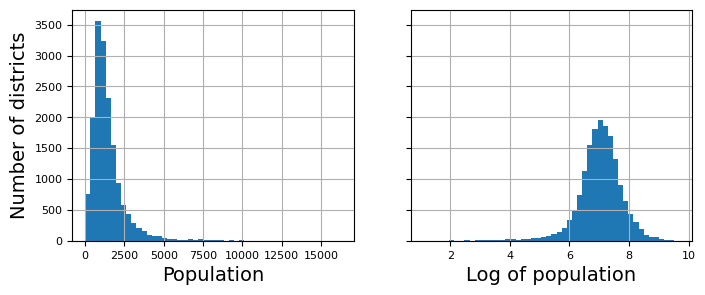

In [64]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
housing["population"].hist(ax=axs[0], bins=50)
housing["population"].apply(np.log).hist(ax=axs[1], bins=50)
axs[0].set_xlabel("Population")
axs[1].set_xlabel("Log of population")
axs[0].set_ylabel("Number of districts")

plt.show()

Another approach to handle heavy-tailed features consists in bucketizing the feature. This means chopping its distribution into roughly equal-sized buckets, and replacing each feature value with the index of the bucket it belongs to, much like we did to create the `income_cat` feature (although we only used it for stratified sampling). For example, you could replace each value with its percentile. Percentiles contain the actual data values that split the dataset into equal-frequency slices. Bucketizing with equal-sized buckets results in a feature with an almost uniform distribution, so there’s no need for further scaling, or you can just divide by the number of buckets to force the values to the 0 - 1 range.

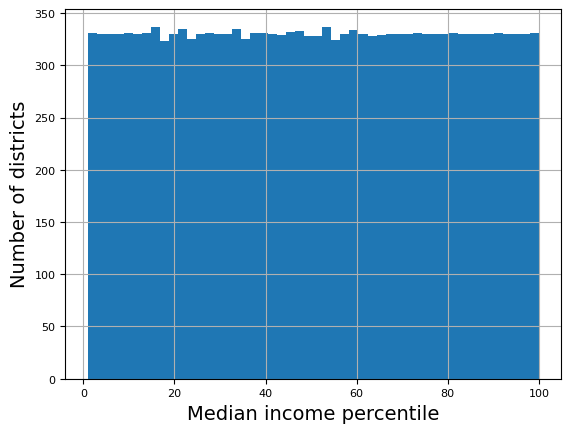

In [65]:
percentiles = [np.percentile(housing["median_income"], p)
               for p in range(1, 100)]
flattened_median_income = pd.cut(housing["median_income"],
                                 bins=[-np.inf] + percentiles + [np.inf],
                                 labels=range(1, 100 + 1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()

**Note**

Incomes below the 1st percentile are labeled 1, and incomes above the 99th percentile are labeled 100. This is why the distribution above ranges from 1 to 100 (not 0 to 100).

When a feature has a multimodal distribution (i.e., with two or more clear peaks, called modes), such as the `housing_median_age` feature, it can also be helpful to bucketize it, but this time treating the bucket IDs as categories, rather than as numerical values. This means that the bucket indices must be encoded, for example using a `OneHotEncoder` (so you usually don’t want to use too many buckets). This approach will allow the regression model to more easily learn different rules for different ranges of this feature value. For example, perhaps houses built around 35 years ago have a peculiar style that fell out of fashion, and therefore they’re cheaper than their age alone would suggest.

Another approach to transforming multimodal distributions is to add a feature for each of the modes (at least the main ones), representing the similarity between the housing median age and that particular mode. The similarity measure is typically computed using a radial basis function (RBF) - any function that depends only on the distance between the input value and a fixed point. The most commonly used RBF is the Gaussian RBF, whose output value decays exponentially as the input value moves away from the fixed point. For example, the Gaussian RBF similarity between the housing age $x$ and 35 is given by the equation $e^{-\gamma (x-35)^2}$. The hyperparameter $\gamma$ (gamma) determines how quickly the similarity measure decays as $x$ moves away from 35. Using Scikit-Learn’s `rbf_kernel()` function, you can create a new Gaussian RBF feature measuring the similarity between the housing median age and 35:

In [66]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(housing[["housing_median_age"]], [[35]], gamma=0.1)

Figure below shows this new feature as a function of the housing median age (solid line). It also shows what the feature would look like if you used a smaller gamma value.

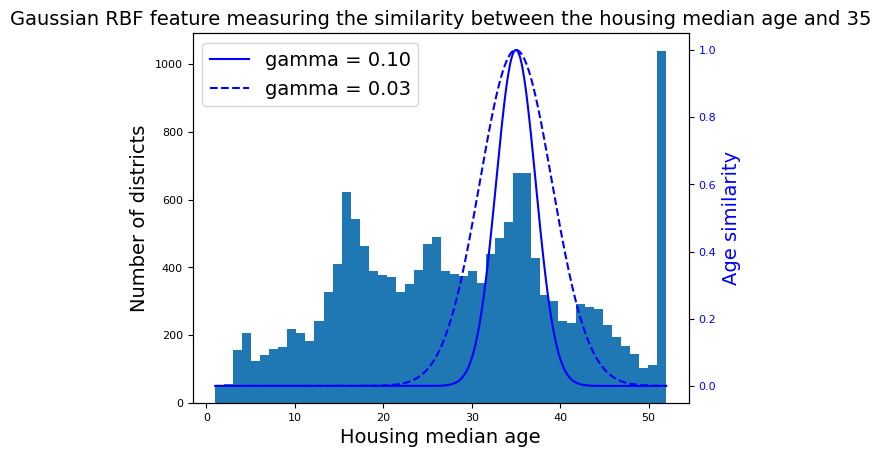

In [67]:
ages = np.linspace(housing["housing_median_age"].min(),
                   housing["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(housing["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # create a twin axis that shares the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")
plt.title("Gaussian RBF feature measuring the similarity between the housing median age and 35")

plt.show()

As the chart shows, the new age similarity feature peaks at 35, right around the spike in the housing median age distribution: if this particular age group is well correlated with lower prices, there’s a good chance that this new feature will help.

So far we’ve only looked at the input features, but the target values may also need to be transformed. For example, if the target distribution has a heavy tail, you may choose to replace the target with its logarithm. But if you do, the regression model will now predict the log of the median house value, not the median house value itself. You will need to compute the exponential of the model’s prediction if you want the predicted median house value.

Luckily, most of Scikit-Learn’s transformers have an `inverse_transform()` method, making it easy to compute the inverse of their transformations. For example, the following code example shows how to scale the labels using a `StandardScaler` (just like we did for inputs), then train a simple linear regression model on the resulting scaled labels and use it to make predictions on some new data, which we transform back to the original scale using the trained scaler’s `inverse_transform()` method. Note that we convert the labels from a Pandas Series to a DataFrame, since the `StandardScaler` expects 2D inputs. Also, in this example we just train the model on a single raw input feature (median income), for simplicity:

In [68]:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(housing[["median_income"]], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]  # pretend this is new data

scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)

print(f"Scaled predictions: {scaled_predictions}")
print(f"Predictions: {predictions}")

Scaled predictions: [[-0.64466228]
 [ 0.80674175]
 [-0.52302364]
 [-0.5853166 ]
 [-0.12415952]]
Predictions: [[131997.15275877]
 [299359.35844434]
 [146023.37185694]
 [138840.33653057]
 [192016.61557639]]


This works fine, but it’s simpler and less error-prone to use a `TransformedTargetRegressor`, avoiding potential scaling mismatches. We just need to construct it, giving it the regression model and the label transformer, then fit it on the training set, using the original unscaled labels. It will automatically use the transformer to scale the labels and train the regression model on the resulting scaled labels, just like we did previously. Then, when we want to make a prediction, it will call the regression model’s `predict()` method and use the scaler’s `inverse_transform()` method to produce the prediction:

In [69]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(
    regressor=LinearRegression(),
    transformer=StandardScaler()
)
model.fit(housing[["median_income"]], housing_labels)
predictions = model.predict(some_new_data)

print(f"Predictions: {predictions}")

Predictions: [131997.15275877 299359.35844434 146023.37185694 138840.33653057
 192016.61557639]


## Custom Transformers

Although Scikit-Learn provides many useful transformers, you will occasionally need to write your own for tasks such as custom transformations, cleanup operations, or combining specific attributes.

For transformations that don’t require any training, you can just write a function that takes a NumPy array as input and outputs the transformed array. For example, as discussed in the previous section, it’s often a good idea to transform features with heavy-tailed distributions by replacing them with their logarithm (assuming the feature is positive and the tail is on the right). Let’s create a log-transformer and apply it to the `population` feature:

In [70]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])

The `inverse_func` argument is optional. It lets you specify an inverse transform function, e.g., if you plan to use your transformer in a `TransformedTargetRegressor`.

Your transformation function can take hyperparameters as additional arguments. For example, here’s how to create a transformer that computes the same Gaussian RBF similarity measure as earlier:

In [71]:
rbf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[[35]], gamma=0.1))

age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])
print(f"age_simil_35: \n{age_simil_35}")

age_simil_35: 
[[2.81118530e-13]
 [8.20849986e-02]
 [6.70320046e-01]
 ...
 [9.55316054e-22]
 [6.70320046e-01]
 [3.03539138e-04]]


Note that there’s no inverse function for the RBF kernel, since there are always two values at a given distance from a fixed point (except at distance 0). Also note that `rbf_kernel()` does not treat the features separately. If you pass it an array with two features, it will measure the 2D distance (Euclidean) to measure similarity. For example, here’s how to add a feature that will measure the geographic similarity between each district and San Francisco:

In [72]:
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel, kw_args=dict(Y=[sf_coords], gamma=0.1))

sf_simil = sf_transformer.transform(housing[["latitude", "longitude"]])
print(f"sf_simil: \n{sf_simil}")

sf_simil: 
[[0.999927  ]
 [0.05258419]
 [0.94864161]
 ...
 [0.00388525]
 [0.05038518]
 [0.99868067]]


Custom transformers are also useful to combine features. For example, here’s a `FunctionTransformer` that computes the ratio between the input features 0 and 1:

In [73]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])

ratio_transformer.transform(np.array([[1, 2], [3, 4]]))

array([[0.5 ],
       [0.75]])

`FunctionTransformer` is very handy, but what if you would like your transformer to be trainable, learning some parameters in the `fit()` method and using them later in the `transform()` method? For this, you need to write a custom class.

We want to define a custom transformer that groups districts into 10 geographical clusters, then measures the distance between each district and the center of each cluster, adding 10 corresponding RBF similarity features to the data.

Scikit-Learn relies on duck typing, so custom transformer classes do not have to inherit from any particular base class. All they need is three methods: `fit()` (which must return `self`), `transform()`, and `fit_transform()`. You can get `fit_transform()` for free by simply adding `TransformerMixin` as a base class: the default implementation will just call `fit()` and then `transform()`. If you add `BaseEstimator` as a base class (and avoid using `*args` and `**kwargs` in your constructor), you will also get two extra methods: `get_params()` and `set_params()`. These will be useful for automatic hyperparameter tuning.

For example, here’s a custom transformer that acts much like the `StandardScaler`:

In [74]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator, TransformerMixin):
    def __init__(self, with_mean=True):  # no *args or **kwargs!
        self.with_mean = with_mean

    def fit(self, X, y=None):  # y is required even though we don't use it
        X = check_array(X)  # checks that X is an array with finite float values
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.n_features_in_ = X.shape[1]  # every estimator stores this in fit()
        return self  # always return self!

    def transform(self, X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

Here are a few things to note:

* The `sklearn.utils.validation` package contains several functions we can use to validate the inputs. For simplicity, we will skip such tests in the rest of this book, but production code should have them.

* Scikit-Learn pipelines require the `fit()` method to have two arguments `X` and `y`, which is why we need the `y=None` argument even though we don’t use `y`.

* All Scikit-Learn estimators set `n_features_in_` in the `fit()` method, and they ensure that the data passed to `transform()` or `predict()` has this number of features.

* The `fit()` method must return `self`.

* This implementation is not 100% complete: all estimators should set `feature_names_in_` in the `fit()` method when they are passed a DataFrame. Moreover, all transformers should provide a `get_feature_names_out()` method, as well as an `inverse_transform()` method when their transformation can be reversed.

A custom transformer can (and often does) use other estimators in its implementation. For example, the following code demonstrates a custom transformer that uses a `KMeans` clusterer in the `fit()` method to identify the main clusters in the training data, and then uses `rbf_kernel()` in the `transform()` method to measure how similar each sample is to each cluster center:

In [75]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

___

**TIP**

You can check whether your custom estimator respects Scikit-Learn’s API by passing an instance to `check_estimator()` from the `sklearn.utils.estimator_checks` package. For the full API, check out [https://scikit-learn.org/stable/developers/](https://scikit-learn.org/stable/developers/).

___

K-means is a clustering algorithm that locates clusters in the data. For example, we can use it to find the most populated regions in California. How many clusters k-means searches for is controlled by the `n_clusters` hyperparameter. The `fit()` method of `KMeans` supports an optional argument `sample_weight`, which lets the user specify the relative weights of the samples. For example, we could pass it the median income if we wanted the clusters to be biased toward wealthy districts. After training, the cluster centers are available via the `cluster_centers_` attribute. K-means is a stochastic algorithm, meaning that it relies on randomness to locate the clusters, so if you want reproducible results, you must set the `random_state` parameter.

Now let’s use this custom transformer:

In [76]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]])

The above code creates a `ClusterSimilarity` transformer, setting the number of clusters to 10. Then it calls `fit_transform()` with the latitude and longitude of every district in the training set (you can try weighting each district by its median income to see how that affects the clusters). The transformer uses k-means to locate the clusters, then measures the Gaussian RBF similarity between each district and all 10 cluster centers. The result is a matrix with one row per district, and one column per cluster.

Let’s look at the first three rows, rounding to two decimal places:

In [77]:
similarities[:3].round(2)

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ],
       [0.  , 0.96, 0.  , 0.03, 0.04, 0.  , 0.  , 0.  , 0.11, 0.35],
       [0.34, 0.  , 0.45, 0.  , 0.  , 0.  , 0.01, 0.73, 0.  , 0.  ]])

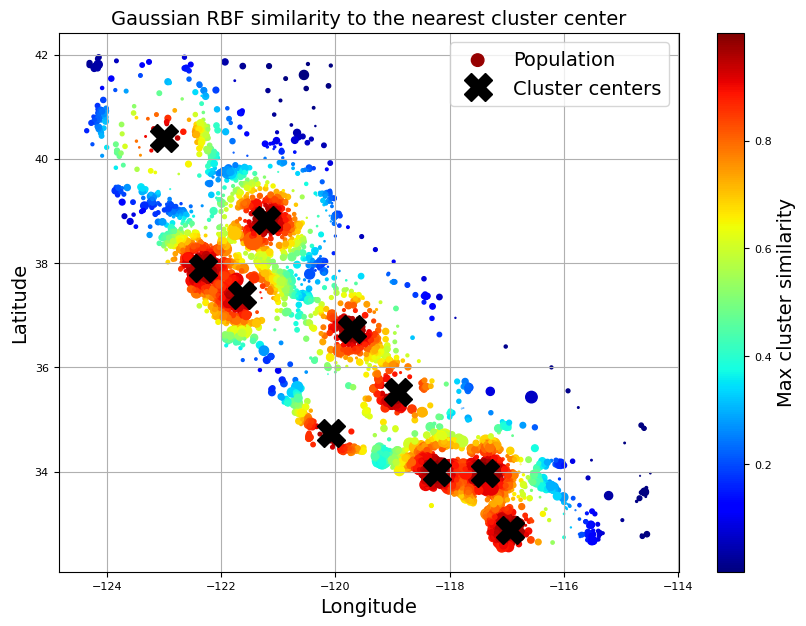

In [78]:
housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)

housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
         cluster_simil.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")
plt.title("Gaussian RBF similarity to the nearest cluster center")

plt.show()

Figure above shows the 10 cluster centers found by k-means. The districts are colored according to their geographic similarity to their closest cluster center. Notice that most clusters are located in highly populated areas.

## Transformation Pipelines

There are many data transformation steps that need to be executed in the right order. Fortunately, Scikit-Learn provides the `Pipeline` class to help with such sequences of transformations. Here is a small pipeline for numerical attributes, which will first impute then scale the input features:

In [79]:
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("standardize", StandardScaler()),
])

The `Pipeline` constructor takes a list of name/estimator pairs (2-tuples) defining a sequence of steps. The names can be anything you like, as long as they are unique and don’t contain double underscores (`__`). The estimators must all be transformers (i.e., they must have a `fit_transform()` method), except for the last one, which can be anything: a transformer, a predictor, or any other type of estimator.

___

**TIP**

In a Jupyter notebook, if you import `sklearn` and run `sklearn.set_config(display="diagram")`, all Scikit-Learn estimators will be rendered as interactive diagrams. This is particularly useful for visualizing pipelines.

In [80]:
num_pipeline

Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('standardize', StandardScaler())])

___

If you don’t want to have to name the transformers, you can use the convenient `make_pipeline()` function instead; it takes transformers as positional arguments and creates a `Pipeline` using the names of the transformers’ classes, in lowercase and without underscores (e.g., `"simpleimputer"`):

In [81]:
from sklearn.pipeline import make_pipeline

num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

In [82]:
num_pipeline

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

When you call the pipeline’s `fit()` method, it calls `fit_transform()` sequentially on all the transformers, passing the output of each call as the parameter to the next call until it reaches the final estimator, for which it just calls the `fit()` method.

Let’s call the pipeline’s `fit_transform()` method and look at the output’s first two rows, rounded to two decimal places:

In [83]:
housing_num_prepared = num_pipeline.fit_transform(housing_numerical)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

As you saw earlier, if you want to recover a nice DataFrame, you can use the pipeline’s `get_feature_names_out()` method:

In [84]:
df_housing_num_prepared = pd.DataFrame(
    housing_num_prepared,
    columns=num_pipeline.get_feature_names_out(),
    index=housing_numerical.index
)
df_housing_num_prepared.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365


Pipelines support indexing; for example, `pipeline[1]` returns the second estimator in the pipeline, and `pipeline[:-1]` returns a `Pipeline` object containing all but the last estimator. You can also access the estimators via the `steps` attribute, which is a list of name/estimator pairs, or via the `named_steps` dictionary attribute, which maps the names to the estimators. For example, `num_pipeline["simpleimputer"]` returns the estimator named `"simpleimputer"`.

In [85]:
num_pipeline[1]

StandardScaler()

In [86]:
num_pipeline[:-1]

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median'))])

In [87]:
num_pipeline.steps

[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler())]

In [88]:
num_pipeline.named_steps

{'simpleimputer': SimpleImputer(strategy='median'),
 'standardscaler': StandardScaler()}

In [89]:
num_pipeline["simpleimputer"]

SimpleImputer(strategy='median')

So far, we have handled the categorical columns and the numerical columns separately. It would be more convenient to have a single transformer capable of handling all columns, applying the appropriate transformations to each column. For this, you can use a `ColumnTransformer`. For example, the following `ColumnTransformer` will apply `num_pipeline` (the one we just defined) to the numerical attributes, and `cat_pipeline` to the categorical attribute. Its constructor requires a list of triplets (3-tuples), each containing a name (which must be unique and not contain double underscores), a transformer, and a list of names (or indices) of columns that the transformer should be applied to:

In [90]:
from sklearn.compose import ColumnTransformer

num_attribs = ["longitude", "latitude", "housing_median_age", "total_rooms",
               "total_bedrooms", "population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"),
)

preprocessing = ColumnTransformer([
    ("numerical", num_pipeline, num_attribs),
    ("categorical", cat_pipeline, cat_attribs),
])

Since listing all the column names is not very convenient, Scikit-Learn provides a `make_column_selector` class that you can use to automatically select all the features of a given type, such as numerical or categorical. You can pass a selector to the `ColumnTransformer` instead of column names or indices. Moreover, if you don’t care about naming the transformers, you can use `make_column_transformer()`, which chooses the names for you, just like `make_pipeline()` does. For example, the following code creates the same `ColumnTransformer` as earlier, except the transformers are automatically named `"pipeline-1"` and `"pipeline-2"` instead of `"numerical"` and `"categorical"`:

In [91]:
from sklearn.compose import make_column_selector, make_column_transformer

preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object)),
)

Now we’re ready to apply this `ColumnTransformer` to the housing data:

In [92]:
housing_prepared = preprocessing.fit_transform(housing)

In [93]:
df_housing_prepared = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing.index
)

df_housing_prepared.head(5)

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0
3785,-1.203098,1.276119,0.351428,-0.712240,-0.760709,-0.788768,-0.775727,-0.759789,0.0,1.0,0.0,0.0,0.0
14689,1.231216,-0.884924,-0.919891,0.702262,0.742306,0.383175,0.731375,-0.850281,0.0,1.0,0.0,0.0,0.0
20507,0.711362,-0.875549,0.589800,0.790125,1.595753,0.444376,1.755263,-0.180365,0.0,0.0,0.0,0.0,1.0


Great! We have a preprocessing pipeline that takes the entire training dataset and applies each transformer to the appropriate columns, then concatenates the transformed columns horizontally (transformers must never change the number of rows). Once again this returns a NumPy array, but you can get the column names using `preprocessing.get_feature_names_out()` and wrap the data in a nice DataFrame as we did before.

___

**Note**

The `OneHotEncoder` returns a sparse matrix and the `num_pipeline` returns a dense matrix. When there is such a mix of sparse and dense matrices, the `ColumnTransformer` estimates the density of the final matrix (i.e., the ratio of nonzero cells), and it returns a sparse matrix if the density is lower than a given threshold (by default, `sparse_threshold=0.3`).

___

Your project is going really well and you’re almost ready to train some models! You now want to create a single pipeline that will perform all the transformations you’ve experimented with up to now. Let’s recap what the pipeline will do and why:

* Missing values in numerical features will be imputed by replacing them with the median, as most ML algorithms don’t expect missing values. In categorical features, missing values will be replaced by the most frequent category.

* The categorical feature will be one-hot encoded, as most ML algorithms only accept numerical inputs.

* A few ratio features will be computed and added: `bedrooms_ratio`, `rooms_per_house`, and `people_per_house`. Hopefully these will better correlate with the median house value, and thereby help the ML models.

* A few cluster similarity features will also be added. These will likely be more useful to the model than latitude and longitude.

* Features with a long tail will be replaced by their logarithm, as most models prefer features with roughly uniform or Gaussian distributions.

* All numerical features will be standardized, as most ML algorithms prefer when all features have roughly the same scale.

The code that builds the pipeline to do all of this should look familiar to you by now:

In [94]:
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in_):
    return ["ratio"]  # feature names out

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler()
    )

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler()
)

cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)

default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

preprocessing = ColumnTransformer([
    ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
    ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
    ("people_per_house", ratio_pipeline(), ["population", "households"]),
    ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population", "households", "median_income"]),
    ("geo", cluster_simil, ["latitude", "longitude"]),
    ("cat", cat_pipeline, make_column_selector(dtype_include=object)),
],
remainder=default_num_pipeline)  # one column remaining: housing_median_age

If you run this `ColumnTransformer`, it performs all the transformations and outputs a NumPy array with 24 features:

In [95]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared.shape

(16512, 24)

In [96]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Select and Train a Model

At last! You framed the problem, you got the data and explored it, you sampled a training set and a test set, and you wrote a preprocessing pipeline to automatically clean up and prepare your data for machine learning algorithms. You are now ready to select and train a machine learning model.

## Train and Evaluate on the Training Set

You decide to train a very basic linear regression model to get started:

In [97]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7f6...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f687d67f440>)])),
                ('linearregression', LinearRegression())])

Done! You now have a working linear regression model. You try it out on the training set, looking at the first five predictions and comparing them to the labels:

In [98]:
housing_predictions = lin_reg.predict(housing)
housing_predictions[:5].round(-2)  # -2 = rounded to the nearest hundred

array([246000., 372700., 135700.,  91400., 330900.])

Compare against the actual values:

In [99]:
housing_labels.iloc[:5].values

array([458300., 483800., 101700.,  96100., 361800.])

In [100]:
error_ratios = (housing_predictions[:5].round(-2) / housing_labels.iloc[:5].values) - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

-46.3%, -23.0%, 33.4%, -4.9%, -8.5%


Well, it works, but not always: the first prediction is way off (by over $200,000!), while the other predictions are better: two are off by about 25%, and two are off by less than 10%.

Remember that you chose to use the RMSE as your performance measure, so you want to measure this regression model’s RMSE on the whole training set using Scikit-Learn’s `root_mean_squared_error()` function:

In [101]:
from sklearn.metrics import root_mean_squared_error

lin_rmse = root_mean_squared_error(housing_labels, housing_predictions)
lin_rmse

68972.88910758484

___

**TIP**

We’re not using the `score()` method here because it returns the $R^2$ *coefficient of determination* instead of the RMSE. This coefficient represents the ratio of the variance in the data that the model can explain: the closer to 1 (which is the max value), the better. If the model simply predicts the mean all the time, it does not explain any part of the variance, so the model’s $R^2$ score is 0. And if the model does even worse than that, then its $R^2$ score can be negative, and indeed arbitrarily low.

___

This is better than nothing, but clearly not a great score: the `median_housing_values` of most districts range between \$120,000 and \$265,000, so a typical prediction error of \$68,973 is really not very satisfying. This is an example of a model underfitting the training data. When this happens it can mean that the features do not provide enough information to make good predictions, or that the model is not powerful enough.

The main ways to fix underfitting are to select a more powerful model, to feed the training algorithm with better features, or to reduce the constraints on the model. This model is not regularized, which rules out the last option. You could try to add more features, but first you want to try a more complex model to see how it does.

You decide to try a `DecisionTreeRegressor`, as this is a fairly powerful model capable of finding complex nonlinear relationships in the data:

In [102]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7f6...
                                                  ClusterSimilarity(random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f687d67f440>)])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=42))])

Now that the model is trained, you evaluate it on the training set:

In [103]:
housing_predictions = tree_reg.predict(housing)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse

0.0

Wait, what!? No error at all? Could this model really be absolutely perfect? Of course, it is much more likely that the model has badly overfit the data. How can you be sure? As you saw earlier, you don’t want to touch the test set until you are ready to launch a model you are confident about, so you need to use part of the training set for training and part of it for model validation.

## Better Evaluation Using Cross-Validation

One way to evaluate the decision tree model would be to use the `train_test_split()` function to split the training set into a smaller training set and a validation set, then train your models against the smaller training set and evaluate them against the validation set. It’s a bit of effort, but nothing too difficult, and it would work fairly well.

A great alternative is to use Scikit-Learn’s k-fold cross-validation feature. You split the training set into k nonoverlapping subsets called folds, then you train and evaluate your model k times, picking a different fold for evaluation every time (i.e., the validation fold) and using the other k - 1 folds for training. This process produces k evaluation scores (see figure below).

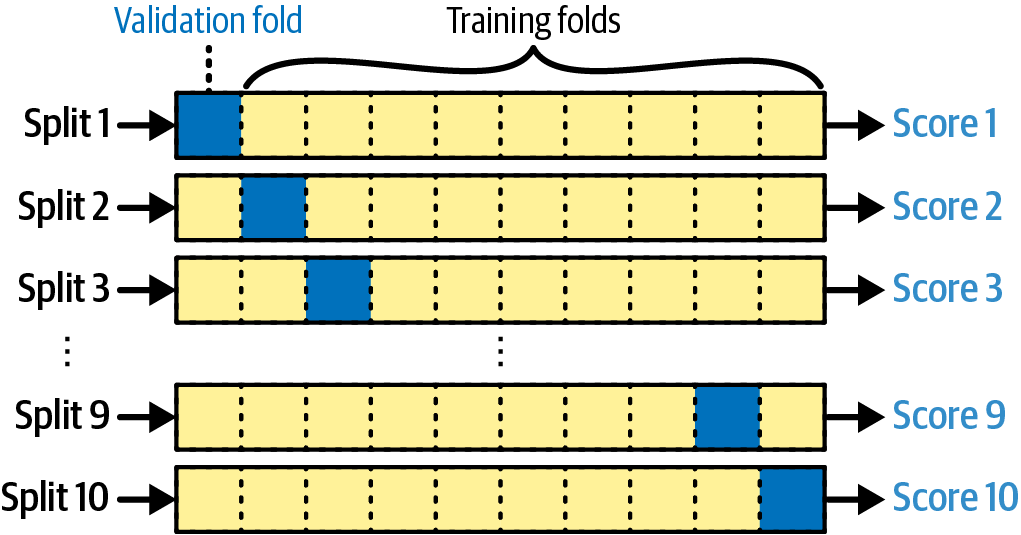

*k-fold cross-validation, with k = 10*

In [105]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/end_to_end_ml_project_04.png", width=500))
display(Markdown("*k-fold cross-validation, with k = 10*"))

Scikit-Learn provides a convenient `cross_val_score()` function that does just that, and it returns an array containing the k evaluation scores. For example, let’s use it to evaluate our tree regressor, using k = 10:

In [106]:
from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(tree_reg, housing, housing_labels, scoring="neg_root_mean_squared_error", cv=10)

___

**WARNING**

Scikit-Learn’s cross-validation features expect a utility function (greater is better) rather than a cost function (lower is better), so the scoring function is actually the opposite of the RMSE. It’s a negative value, so you need to switch the sign of the output to get the RMSE scores.

___

Let’s look at the results:

In [107]:
pd.Series(tree_rmses).describe()

,0
count,10.000000
mean,66573.734600
std,1103.402323
min,64607.896046
25%,66204.731788
50%,66388.272499
75%,66826.257468
max,68532.210664


Now the decision tree doesn’t look as good as it did earlier. In fact, it seems to perform almost as poorly as the linear regression model! Notice that cross-validation allows you to get not only an estimate of the performance of your model, but also a measure of how precise this estimate is (i.e., its standard deviation). The decision tree has an RMSE of about 66,574, with a standard deviation of about 1,103. You would not have this information if you just used one validation set. But cross-validation comes at the cost of training the model several times, so it is not always feasible.

We can compute the same metric for linear regression model:

In [108]:
lin_rmses = -cross_val_score(lin_reg, housing, housing_labels, scoring="neg_root_mean_squared_error", cv=10)
pd.Series(lin_rmses).describe()

,0
count,10.000000
mean,70003.404818
std,4182.188328
min,65504.765753
25%,68172.065831
50%,68743.995249
75%,70344.943988
max,81037.863741


We find that the mean RMSE is 70,003 and the standard deviation is 4,182. So the decision tree model seems to perform very slightly better than the linear model, but the difference is minimal due to severe overfitting. We know there’s an overfitting problem because the training error is low (actually zero) while the validation error is high.

Let’s try one last model now: the `RandomForestRegressor`. Random forests work by training many decision trees on random subsets of the features, then averaging out their predictions. Such models composed of many other models are called ensembles: if the underlying models are very diverse, then their errors will not be very correlated, and therefore averaging out the predictions will smooth out the errors, reduce overfitting, and improve the overall performance. The code is much the same as earlier:

In [109]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = make_pipeline(preprocessing, RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg, housing, housing_labels, scoring="neg_root_mean_squared_error", cv=10)

Let’s look at the scores:

In [110]:
pd.Series(forest_rmses).describe()

,0
count,10.000000
mean,47038.092799
std,1021.491757
min,45495.976649
25%,46510.418013
50%,47118.719249
75%,47480.519175
max,49140.832210


Wow, this is much better: random forests really look very promising for this task! Now, let's compare this RMSE measured using cross-validation (the "validation error") with the RMSE measured on the training set (the "training error"):

In [111]:
forest_reg.fit(housing, housing_labels)
housing_predictions = forest_reg.predict(housing)
forest_rmse = root_mean_squared_error(housing_labels, housing_predictions)
forest_rmse

17551.2122500877

The training error is much lower than the validation error, which usually means that the model has overfit the training set. Another possible explanation may be that there's a mismatch between the training data and the validation data, but it's not the case here, since both came from the same dataset that we shuffled and split in two parts. Possible solutions are to simplify the model, constrain it (i.e., regularize it), or get a lot more training data.

Before you dive much deeper into random forests, however, you should try out many other models from various categories of machine learning algorithms (e.g., several support vector machines with different kernels, and possibly a neural network), without spending too much time tweaking the hyperparameters. The goal is to shortlist a few (two to five) promising models.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Fine-Tune Your Model

Let’s assume that you now have a shortlist of promising models. You now need to fine-tune them. Let’s look at a few ways you can do that.

## Grid Search

One option would be to fiddle with the hyperparameters manually, until you find a great combination of hyperparameter values. This would be very tedious work, and you may not have time to explore many combinations.

Instead, you can use Scikit-Learn’s `GridSearchCV` class to search for you. All you need to do is tell it which hyperparameters you want it to experiment with and what values to try out, and it will use cross-validation to evaluate all the possible combinations of hyperparameter values. For example, the following code searches for the best combination of hyperparameter values for the `RandomForestRegressor`:

In [112]:
from sklearn.model_selection import GridSearchCV

full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]}
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3, scoring="neg_root_mean_squared_error")
grid_search.fit(housing, housing_labels)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                     SimpleImputer(strategy='median')),
                                                                                    ('standardscaler',
                                                                                     StandardScaler())]),
                                                          transformers=[('bedrooms',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('functiontransformer',
                                                                                          FunctionTransformer(feature_names_out=<f...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x7f687d67f440>)])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'preprocessing__geo__n_clusters': [5, 8, 10],
                          'random_forest__max_features': [4, 6, 8]},
                         {'preprocessing__geo__n_clusters': [10, 15],
                          'random_forest__max_features': [6, 8, 10]}],
             scoring='neg_root_mean_squared_error')

Notice that you can refer to any hyperparameter of any estimator in a pipeline, even if this estimator is nested deep inside several pipelines and column transformers. For example, when Scikit-Learn sees `"preprocessing__geo__n_clusters"`, it splits this string at the double underscores, then it looks for an estimator named `"preprocessing"` in the pipeline and finds the preprocessing `ColumnTransformer`. Next, it looks for a transformer named `"geo"` inside this `ColumnTransformer` and finds the `ClusterSimilarity` transformer we used on the latitude and longitude attributes. Then it finds this transformer’s `n_clusters` hyperparameter. Similarly, `random_forest__max_features` refers to the `max_features` hyperparameter of the estimator named `"random_forest"`, which is of course the `RandomForestRegressor` model.

There are two dictionaries in this `param_grid`, so `GridSearchCV` will first evaluate all 3 × 3 = 9 combinations of `n_clusters` and `max_features` hyperparameter values specified in the first `dict`, then it will try all 2 × 3 = 6 combinations of hyperparameter values in the second `dict`. So in total the grid search will explore 9 + 6 = 15 combinations of hyperparameter values.

You can get the full list of hyperparameters available for tuning by looking at `full_pipeline.get_params().keys()`:

In [113]:
# Shows part of the output of get_params().keys()
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

It will train the pipeline 3 times per combination, since we are using 3-fold cross validation. This means there will be a grand total of 15 × 3 = 45 rounds of training! It may take a while, but when it is done you can get the best combination of parameters like this:

In [114]:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}

In this example, the best model is obtained by setting `n_clusters` to 15 and setting `max_features` to 6.

___

**TIP**

Since 15 is the maximum value that was evaluated for `n_clusters`, you should probably try searching again with higher values; the score may continue to improve.

___

You can access the best estimator using `grid_search.best_estimator_`.

In [115]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7f687cf...
                                                  ClusterSimilarity(n_clusters=15,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f6880523b30>)])),
                ('random_forest',
                 RandomForestRegressor(max_features=6, random_state=42))])

If `GridSearchCV` is initialized with `refit=True` (which is the default), then once it finds the best estimator using cross-validation, it retrains it on the whole training set. This is usually a good idea, since feeding it more data will likely improve its performance.

The evaluation scores are available using `grid_search.cv_results_`. This is a dictionary, but if you wrap it in a DataFrame you get a nice list of all the test scores for each combination of hyperparameters and for each cross-validation split, as well as the mean test score across all splits:

In [116]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# change column names to fit on this page
cv_res = cv_res[[
    "param_preprocessing__geo__n_clusters", "param_random_forest__max_features",
    "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score"
]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,42725,43708,44335,43590
13,15,8,43486,43820,44900,44069
6,10,4,43798,44036,44961,44265
9,10,6,43710,44163,44967,44280
7,10,6,43710,44163,44967,44280


The mean test RMSE score for the best model is 43,590, which is better than the score you got earlier using the default hyperparameter values (which was 47,038). Congratulations, you have successfully fine-tuned your best model!

## Randomized Search

The grid search approach is fine when you are exploring relatively few combinations, like in the previous example, but `RandomizedSearchCV` is often preferable, especially when the hyperparameter search space is large. This class can be used in much the same way as the `GridSearchCV` class, but instead of trying out all possible combinations it evaluates a fixed number of combinations, selecting a random value for each hyperparameter at every iteration. This may sound surprising, but this approach has several benefits:

If some of your hyperparameters are continuous (or discrete but with many possible values), and you let randomized search run for, say, 1,000 iterations, then it will explore 1,000 different values for each of these hyperparameters, whereas grid search would only explore the few values you listed for each one.

Suppose a hyperparameter does not actually make much difference, but you don’t know it yet. If it has 10 possible values and you add it to your grid search, then training will take 10 times longer. But if you add it to a random search, it will not make any difference.

If there are 6 hyperparameters to explore, each with 10 possible values, then grid search offers no other choice than training the model a million times, whereas random search can always run for any number of iterations you choose.

For each hyperparameter, you must provide either a list of possible values, or a probability distribution:

In [117]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {
    'preprocessing__geo__n_clusters': randint(low=3, high=50),
    'random_forest__max_features': randint(low=2, high=20)
}

rnd_search = RandomizedSearchCV(
    full_pipeline, param_distributions=param_distribs, n_iter=10, cv=3,
    scoring="neg_root_mean_squared_error", random_state=42
)
rnd_search.fit(housing, housing_labels)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'preprocessing__geo__n_clusters': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f6880868e60>,
                                        'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7f687ceeb5f0>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [118]:
rnd_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x7f687cf...
                                                  ClusterSimilarity(n_clusters=45,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7f688072e2d0>)])),
                ('random_forest',
                 RandomForestRegressor(max_features=9, random_state=42))])

In [119]:
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)

# change column names to fit on this page
cv_res = cv_res[[
    "param_preprocessing__geo__n_clusters", "param_random_forest__max_features",
    "split0_test_score", "split1_test_score", "split2_test_score", "mean_test_score"
]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)

cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
1,45,9,41342,42242,43057,42214
8,32,7,41825,42275,43241,42447
0,41,16,42238,42938,43354,42843
5,42,4,41869,43362,43664,42965
2,23,8,42490,42928,43718,43046


Scikit-Learn also has `HalvingRandomSearchCV` and `HalvingGridSearchCV` hyperparameter search classes. Their goal is to use the computational resources more efficiently, either to train faster or to explore a larger hyperparameter space. Here’s how they work: in the first round, many hyperparameter combinations (called “candidates”) are generated using either the grid approach or the random approach. These candidates are then used to train models that are evaluated using cross-validation, as usual. However, training uses limited resources, which speeds up this first round considerably. By default, “limited resources” means that the models are trained on a small part of the training set. However, other limitations are possible, such as reducing the number of training iterations if the model has a hyperparameter to set it. Once every candidate has been evaluated, only the best ones go on to the second round, where they are allowed more resources to compete. After several rounds, the final candidates are evaluated using full resources. This may save you some time tuning hyperparameters.

## Ensemble Methods

Another way to fine-tune your system is to try to combine the models that perform best. The group (or “ensemble”) will often perform better than the best individual model - just like random forests perform better than the individual decision trees they rely on—especially if the individual models make very different types of errors. For example, you could train and fine-tune a k-nearest neighbors model, then create an ensemble model that just predicts the mean of the random forest prediction and that model’s prediction.

## How to Choose the Sampling Distribution for a Hyperparameter

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# References

- **Hands-On Machine Learning with Scikit-Learn and PyTorch by Aurélien Géron**

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)